## Mount & Path

In [1]:
# from google.colab import drive
# drive.mount('/content/drive')

# path_file  = '/content/drive/MyDrive/tesisugm/no-leakage/' #google colab
path_file = ''  # local

KOMPOSISI  = "lightgbm_astra_radiant"

## Load Features Module

In [2]:
def load_module(module_name, path):
    import importlib.util, sys

    spec = importlib.util.spec_from_file_location(module_name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[module_name] = module
    spec.loader.exec_module(module)

    print("Features file   :", module.__file__)
    print("Features version:", getattr(module, "FEATURES_VERSION", "latest update"))

    return module

features = load_module("features", f"{path_file}features.py")
utils_ml = load_module("utils_ml", f"{path_file}utils_ml.py")
hybrid_oversampling = load_module("hybrid_oversampling", f"{path_file}hybrid_oversampling.py")

Features file   : features.py
Features version: Shami Extractor
Features file   : utils_ml.py
Features version: utils_ml_0.2.6
Features file   : hybrid_oversampling.py
Features version: latest update


## Imports

In [3]:
import os, gc, warnings, hashlib, itertools, time, math
import numpy as np
import pandas as pd
import lightgbm as lgb
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from scipy.sparse import hstack, csr_matrix, issparse, vstack, diags
from sklearn.model_selection  import train_test_split
from sklearn.preprocessing    import LabelEncoder, normalize
from sklearn.metrics          import (accuracy_score, f1_score,
                                      classification_report, confusion_matrix,
                                      silhouette_score)
from sklearn.cluster          import MiniBatchKMeans
from sklearn.neighbors        import NearestNeighbors
from sklearn.utils            import check_random_state
import matplotlib.patches as mpatches
from features import ShamiFeatureExtractor, clean_noise, clean_char

from utils_ml import *

# Set environment variable
os.environ['PYTHONWARNINGS'] = 'ignore'

# Suppress all warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

# Specific sklearn warnings
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')
warnings.filterwarnings('ignore', module='sklearn.utils.validation')

# Your existing code
from sklearn.exceptions import DataConversionWarning
warnings.filterwarnings('ignore', message='X does not have valid feature names')

warnings.filterwarnings("ignore")
print("Libraries loaded.")

Libraries loaded.


## Inisiasi Path

In [4]:
# ROOT
BASE_DIR = os.path.join(path_file, "artifacts")

# GLOBAL SAVE
SAVE_DIR = os.path.join(BASE_DIR, "output")

# JOINT LOAD
JOINT_DIR = os.path.join(BASE_DIR, "joint_search")
JOINT_DOCS_DIR = os.path.join(JOINT_DIR, "docs")

# PER KOMPOSISI
KOMPOSISI_DIR = os.path.join(BASE_DIR, KOMPOSISI)

# SUB DIR
MODEL_DIR = os.path.join(KOMPOSISI_DIR, "model")
IMAGE_DIR = os.path.join(KOMPOSISI_DIR, "image")
DOCS_DIR  = os.path.join(KOMPOSISI_DIR, "docs")

# CREATE ALL
for d in [SAVE_DIR, KOMPOSISI_DIR, MODEL_DIR, IMAGE_DIR, DOCS_DIR]:
    os.makedirs(d, exist_ok=True)

print("✅ Semua path berhasil diinisialisasi!")

✅ Semua path berhasil diinisialisasi!


In [5]:
def save_and_show(name):
    path = os.path.join(IMAGE_DIR, f"{name}.png")
    plt.savefig(path, dpi=300, bbox_inches='tight')
    print(f"🖼️ Saved: {path}")
    plt.show()
    plt.close()

def global_image(name):
    path = os.path.join(SAVE_DIR, f"{name}.png")
    plt.savefig(path, dpi=300, bbox_inches='tight')
    print(f"🖼️ Saved: {path}")
    plt.show()
    plt.close()

## Data Preparation

In [6]:
df = pd.read_csv(f'{path_file}../dataset/shami_preprocessed_dataset_raw.csv')
df = (
    df.dropna(subset=["text", "label"])
      .rename(columns={"label": "country"})
)
df["clean_word"] = df["text"].apply(clean_noise)
df["clean_char"] = df["text"].apply(clean_char)

try:    display(df.head())
except: print(df.head())
display(df['country'].value_counts(normalize=True))

,text,country,clean_word,clean_char
0,هه اصلا حاليا في وفد قطري موجود بغزه واللعبه ه...,Palestine,هه اصلا حاليا في وفد قطري موجود بغزه واللعبه ه...,هه اصلا حاليا في وفد قطري موجود بغزه واللعبه ه...
1,عادي طعميها لانها ما راح تكتفي من صدرك صار بده...,Palestine,عادي طعميها لانها ما راح تكتفي من صدرك صار بده...,عادي طعميها لانها ما راح تكتفي من صدرك صار بده...
2,اعملي اللي عليكي لوجه الله,Palestine,اعملي اللي عليكي لوجه الله,اعملي اللي عليكي لوجه الله
3,حكت شفتها اكتر من مره بلبس قصير واكيد زوجي شافها,Palestine,حكت شفتها اكتر من مره بلبس قصير واكيد زوجي شافها,حكت شفتها اكتر من مره بلبس قصير واكيد زوجي شافها
4,و هيا واياه بتزوجو هه,Palestine,و هيا واياه بتزوجو هه,و هيا واياه بتزوجو هه


country
Syria        0.569973
Lebanon      0.163464
Palestine    0.160641
Jordan       0.105922
Name: proportion, dtype: float64

### Class distribution plot

🖼️ Saved: artifacts/output/class_distribution.png


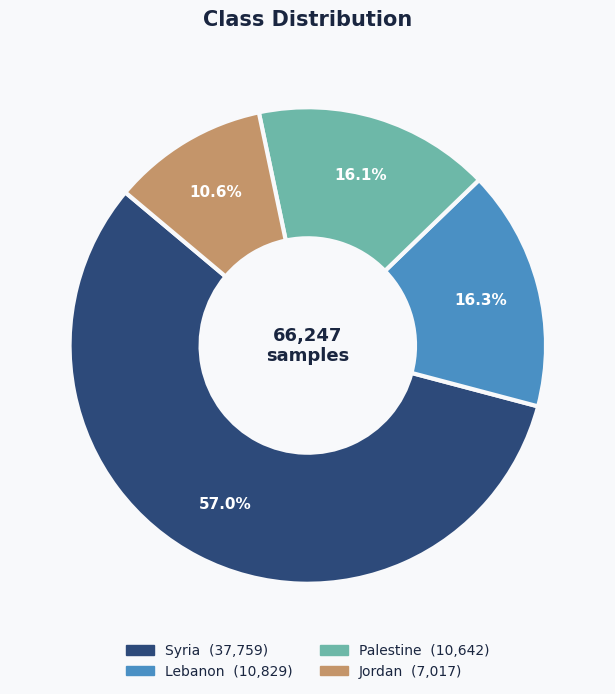

In [7]:
class_dist = df['country'].value_counts()

fig, ax = plt.subplots(figsize=(7, 7), facecolor=BG_COLOR)
wedges, texts, autotexts = ax.pie(
    class_dist,
    labels=None,
    autopct='%1.1f%%',
    startangle=140,
    colors=PALETTE,
    pctdistance=0.75,
    wedgeprops=dict(width=0.55, edgecolor=BG_COLOR, linewidth=3),
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight("bold")
    at.set_color("white")

# Centre label
ax.text(0, 0, f"{class_dist.sum():,}\nsamples",
        ha='center', va='center', fontsize=13,
        fontweight='bold', color=TEXT_DARK)

# Legend
legend_labels = [f"{c}  ({v:,})" for c, v in class_dist.items()]
patches = [mpatches.Patch(color=PALETTE[i], label=legend_labels[i])
           for i in range(len(class_dist))]
ax.legend(handles=patches, loc="lower center", bbox_to_anchor=(0.5, -0.08),
          ncol=2, frameon=False, fontsize=10)

ax.set_title("Class Distribution", fontsize=15, fontweight='bold',
             color=TEXT_DARK, pad=16)
fig.tight_layout()
global_image("class_distribution")

### Split

In [8]:
X = df[["text", "clean_word", "clean_char"]]
y = df["country"]

le          = LabelEncoder()
y_encoded   = le.fit_transform(y)
label_names = le.classes_
label_mapping   = {label: idx  for idx, label in enumerate(label_names)}
class_name_map  = {i: name     for i, name   in enumerate(label_names)}
print("Label mapping:", label_mapping)

from collections import Counter

def print_class_distribution(y_data, title):
    counter = Counter(y_data)
    print(f"\n=== {title} ===")
    total = len(y_data)
    for cls_id in sorted(counter.keys()):
        cls_name = class_name_map[cls_id]
        count    = counter[cls_id]
        print(f"{cls_id} ({cls_name}) : {count} ({count/total*100:.2f}%)")
    print("Total :", total)

print_class_distribution(y_encoded, "BEFORE SPLIT")

X_train_full, X_test,  y_train_full, y_test  = train_test_split(
    X, y_encoded, test_size=0.25, stratify=y_encoded, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.20,
    stratify=y_train_full, random_state=42)

print_class_distribution(y_train, "TRAIN SET")
print_class_distribution(y_val,   "VALIDATION SET")
print_class_distribution(y_test,  "TEST SET")

Label mapping: {'Jordan': 0, 'Lebanon': 1, 'Palestine': 2, 'Syria': 3}

=== BEFORE SPLIT ===
0 (Jordan) : 7017 (10.59%)
1 (Lebanon) : 10829 (16.35%)
2 (Palestine) : 10642 (16.06%)
3 (Syria) : 37759 (57.00%)
Total : 66247

=== TRAIN SET ===
0 (Jordan) : 4210 (10.59%)
1 (Lebanon) : 6498 (16.35%)
2 (Palestine) : 6385 (16.06%)
3 (Syria) : 22655 (57.00%)
Total : 39748

=== VALIDATION SET ===
0 (Jordan) : 1053 (10.60%)
1 (Lebanon) : 1624 (16.34%)
2 (Palestine) : 1596 (16.06%)
3 (Syria) : 5664 (57.00%)
Total : 9937

=== TEST SET ===
0 (Jordan) : 1754 (10.59%)
1 (Lebanon) : 2707 (16.34%)
2 (Palestine) : 2661 (16.07%)
3 (Syria) : 9440 (57.00%)
Total : 16562


## Feature Extraction

In [9]:
CHI2_PCT             = 0.015
MI_PCT23             = 0.010
MI_PCT45             = 0.015
USE_OOF_INTERACTION = True   # flag diteruskan ke ShamiFeatureExtractor

split_hash = hashlib.md5(pd.util.hash_pandas_object(X_train["text"]).values).hexdigest()[:10]
base_signature = f"{features.FEATURES_VERSION}_{split_hash}"
base_cache_dir = os.path.join(path_file, "cache", base_signature)
os.makedirs(base_cache_dir, exist_ok=True)

feat_cache_key = (
    f"chi2_{CHI2_PCT}_mi23_{MI_PCT23}_mi45_{MI_PCT45}"
    f"_oof_inter_{int(USE_OOF_INTERACTION)}"
)
data_hash = hashlib.md5(df["text"].str.cat().encode()).hexdigest()[:8]

feat_cache_dir = os.path.join(
    base_cache_dir,
    feat_cache_key,
    data_hash
)

os.makedirs(feat_cache_dir, exist_ok=True)
print("Base signature :", base_signature)
print("Feat cache dir :", feat_cache_dir)

feat_path = os.path.join(base_cache_dir, "feature_extractor.pkl")
if os.path.exists(feat_path):
    print("✅ Loading base extractor...")
    feat = joblib.load(feat_path)
else:
    print("⚙️ Building base extractor (MI fit bisa makan waktu 2-5 menit)...")
    feat = ShamiFeatureExtractor(
        chi2_pct=CHI2_PCT,
        mi_pct23=MI_PCT23,
        mi_pct45=MI_PCT45,
        use_oof_lr=True,
        use_oof_interaction=USE_OOF_INTERACTION,
    )
    feat.fit(X_train, y_train)
    joblib.dump(feat, feat_path)
print("Base extractor ready.")

Base signature : Shami Extractor_0890ac2785
Feat cache dir : cache/Shami Extractor_0890ac2785/chi2_0.015_mi23_0.01_mi45_0.015_oof_inter_1/6ace3dc3
✅ Loading base extractor...
Base extractor ready.


### Update k

In [10]:
feat.update_chi2_pct(CHI2_PCT)
feat.update_mi_pct(new_pct23=MI_PCT23, new_pct45=MI_PCT45)

# ---- Info dimensi ----
print("\nMI info     :", feat.mi_info)
print("Block sizes :", feat.block_sizes)

[update] chi2_pct=1.50% -> chi2_k=2,420
[update] mi_pct23=1.00% -> mi_k23=500
[update] mi_pct45=1.50% -> mi_k45=2,650

MI info     : {'chi2_pct': 0.015, 'chi2_k_eff': 2420, 'mi_pct23': 0.01, 'mi_k23_eff': 500, 'char23_vocab': 10964, 'char23_selected': 500, 'mi_pct45': 0.015, 'mi_k45_eff': 2650, 'char45_vocab': 176676, 'char45_selected': 2650}
Block sizes : {'lexical': 2420, 'char_mi23': 500, 'char_mi45': 2650, 'doc_stats': 7, 'stopword': 2, 'morph': 26, 'morph_inter': 8, 'colloc_dom': 1, 'nbsvm': 4, 'oof_lr': 8, 'oof_svm': 8, 'oof_interactions': 10}


### Lexical Info

In [11]:
dims = {
    "tfidf_wL_uni": len(feat.tfidf_wL_uni.vocabulary_),
    "tfidf_wL_23" : len(feat.tfidf_wL_23.vocabulary_),
    "tfidf_wA_uni": len(feat.tfidf_wA_uni.vocabulary_),
    "tfidf_wA_23" : len(feat.tfidf_wA_23.vocabulary_),
    "tfidf_char"  : len(feat.tfidf_char.vocabulary_),
    "bm25_word"   : len(feat.bm25w.cv.vocabulary_),
    "bm25_char"   : len(feat.bm25c.cv.vocabulary_),
}
print("\n==============================")
print("LEXICAL FEATURES BEFORE CHI2")
print("==============================")
for k, v in dims.items():
    print(f"{k:15s}: {v:,}")
print(f"\nLEXICAL total  : {sum(dims.values()):,}")

ranges = {}
start  = 0
for name, size in dims.items():
    ranges[name] = (start, start + size)
    start += size
counts = {k: 0 for k in dims}
for c in feat._chi2_cols:
    for name, (s, e) in ranges.items():
        if s <= c < e:
            counts[name] += 1
            break
print("\n==============================")
print("LEXICAL FEATURES AFTER CHI2")
print("==============================")
for k, v in counts.items():
    print(f"{k:15s}: {v:,}")
print(f"\nTotal chi2 selected: {len(feat._chi2_cols):,}")


LEXICAL FEATURES BEFORE CHI2
tfidf_wL_uni   : 19,234
tfidf_wL_23    : 19,234
tfidf_wA_uni   : 19,226
tfidf_wA_23    : 19,226
tfidf_char     : 34,631
bm25_word      : 40,562
bm25_char      : 9,272

LEXICAL total  : 161,385

LEXICAL FEATURES AFTER CHI2
tfidf_wL_uni   : 115
tfidf_wL_23    : 115
tfidf_wA_uni   : 115
tfidf_wA_23    : 115
tfidf_char     : 843
bm25_word      : 316
bm25_char      : 801

Total chi2 selected: 2,420


In [12]:
print("\n==============================")
print("CHAR FEATURES BEFORE MI")
print("==============================")

print(f"char_2_3 vocab: {feat._X_char23_tr.shape[1]:,}")
print(f"char_4_5 vocab: {feat._X_char45_tr.shape[1]:,}")
print(f"Total char    : {feat._X_char23_tr.shape[1] + feat._X_char45_tr.shape[1]:,}")

print("\n==============================")
print("CHAR FEATURES AFTER MI")
print("==============================")

print(f"char_mi23: {feat._mi_sel23.n_selected:,}")
print(f"char_mi45: {feat._mi_sel45.n_selected:,}")
print(f"Total MI  : {feat._mi_sel23.n_selected + feat._mi_sel45.n_selected:,}")


CHAR FEATURES BEFORE MI
char_2_3 vocab: 10,964
char_4_5 vocab: 176,676
Total char    : 187,640

CHAR FEATURES AFTER MI
char_mi23: 500
char_mi45: 2,650
Total MI  : 3,150


### Build / Load Feature Matrices

In [13]:
xtr_path  = os.path.join(feat_cache_dir, "Xtr_feat.pkl")
xval_path = os.path.join(feat_cache_dir, "Xval_feat.pkl")
xte_path  = os.path.join(feat_cache_dir, "Xte_feat.pkl")
ytr_path  = os.path.join(feat_cache_dir, "y_train.pkl")
yval_path = os.path.join(feat_cache_dir, "y_val.pkl")
yte_path  = os.path.join(feat_cache_dir, "y_test.pkl")

if all(os.path.exists(p) for p in [xtr_path, xval_path, xte_path,
                                    ytr_path, yval_path, yte_path]):
    print("✅ Loading feature matrices from cache...")
    Xtr_feat  = joblib.load(xtr_path)
    Xval_feat = joblib.load(xval_path)
    Xte_feat  = joblib.load(xte_path)
    y_train   = joblib.load(ytr_path)
    y_val     = joblib.load(yval_path)
    y_test    = joblib.load(yte_path)
else:
    print("⚙️ Building feature matrices...")
    # feat.transform() output:
    # [lexical_chi2 | char_mi23 | char_mi45 | structural | oof_lr | oof_svm | oof_interactions]
    Xtr_feat  = feat.transform(X_train, is_train=True)
    Xval_feat = feat.transform(X_val,   is_train=False)
    Xte_feat  = feat.transform(X_test,  is_train=False)
    gc.collect()
    joblib.dump(Xtr_feat,  xtr_path)
    joblib.dump(Xval_feat, xval_path)
    joblib.dump(Xte_feat,  xte_path)
    joblib.dump(y_train,   ytr_path)
    joblib.dump(y_val,     yval_path)
    joblib.dump(y_test,    yte_path)

print(f"Train shape : {Xtr_feat.shape}")
print(f"Val shape   : {Xval_feat.shape}")
print(f"Test shape  : {Xte_feat.shape}")

✅ Loading feature matrices from cache...
Train shape : (39748, 5644)
Val shape   : (9937, 5644)
Test shape  : (16562, 5644)


### Block Ablation Utilities

In [14]:
def build_block_slices(block_sizes):
    slices = {}
    start  = 0
    for name, size in block_sizes.items():
        slices[name] = (start, start + size)
        start += size
    return slices

def drop_blocks(X, block_slices, drop_list):
    keep_cols = []
    for name, (s, e) in block_slices.items():
        if name not in drop_list:
            keep_cols.extend(range(s, e))
        else:
            print(f"  Dropping block: {name}  size={e - s:,}")
    keep_cols = np.array(keep_cols)
    return X[:, keep_cols], keep_cols

block_slices = build_block_slices(feat.block_sizes)
print("\nBlock slices:")
for k, (s, e) in block_slices.items():
    print(f"  {k:20s}: cols {s:5d}–{e:5d}  ({e - s:,})")


Block slices:
  lexical             : cols     0– 2420  (2,420)
  char_mi23           : cols  2420– 2920  (500)
  char_mi45           : cols  2920– 5570  (2,650)
  doc_stats           : cols  5570– 5577  (7)
  stopword            : cols  5577– 5579  (2)
  morph               : cols  5579– 5605  (26)
  morph_inter         : cols  5605– 5613  (8)
  colloc_dom          : cols  5613– 5614  (1)
  nbsvm               : cols  5614– 5618  (4)
  oof_lr              : cols  5618– 5626  (8)
  oof_svm             : cols  5626– 5634  (8)
  oof_interactions    : cols  5634– 5644  (10)


In [15]:
# ---- Ubah drop_list untuk ablasi ----
drop_list = []
if drop_list:
    print("\nDropping blocks:", drop_list)
    Xtr_sel,  _         = drop_blocks(Xtr_feat,  block_slices, drop_list)
    Xval_sel, _         = drop_blocks(Xval_feat, block_slices, drop_list)
    Xte_sel,  kept_cols = drop_blocks(Xte_feat,  block_slices, drop_list)
else:
    print("\nNo block dropped.")
    Xtr_sel   = Xtr_feat
    Xval_sel  = Xval_feat
    Xte_sel   = Xte_feat
    kept_cols = np.arange(Xtr_feat.shape[1])


No block dropped.


In [16]:
# ============================================================
## SVD (opsional, default OFF)
# ============================================================
USE_SVD = False
if USE_SVD:
    from sklearn.decomposition import TruncatedSVD
    print("\nApplying SVD compression...")
    svd      = TruncatedSVD(n_components=200, random_state=42)
    Xtr_sel  = svd.fit_transform(Xtr_sel)
    Xval_sel = svd.transform(Xval_sel)
    Xte_sel  = svd.transform(Xte_sel)
    print(f"Train: {Xtr_sel.shape}")
else:
    print("Skipping SVD (recommended for LightGBM)")
    print(f"Train: {Xtr_sel.shape}")

Skipping SVD (recommended for LightGBM)
Train: (39748, 5644)


## ASTRA-RADIANT

### Load Artifacts & Config

In [17]:
# ── Load artifacts dari joint_search ─────────────────────────
best_params       = joblib.load(os.path.join(SAVE_DIR, "lightgbm_original_best_params.pkl"))
BEST_ASTRA_CONFIG = joblib.load(os.path.join(SAVE_DIR, "best_astra_smote_config.pkl"))
BEST_RADIANT_CONFIG = joblib.load(os.path.join(SAVE_DIR, "best_smote_radiant_config.pkl"))

### Apply KNSmote dengan Best Config

In [18]:
from collections import Counter
import numpy as np
import time

from hybrid_oversampling import ASTRA_SMOTE, SMOTE_RADIANT


# ============================================================
# 1. Konversi parameter RADIANT
# ============================================================
eps_val = BEST_RADIANT_CONFIG["eps"]
min_samp_val = BEST_RADIANT_CONFIG["min_samples"]

eps_val = "auto" if eps_val == "auto" else float(eps_val)
min_samp_val = (
    "auto"
    if min_samp_val == "auto"
    else int(min_samp_val)
)


# ============================================================
# 2. Tahap preventif: ASTRA-SMOTE
# ============================================================
print("\n" + "=" * 70)
print("TAHAP 1 — ASTRA-SMOTE GENERATION")
print("=" * 70)

t_astra_start = time.perf_counter()

astra = ASTRA_SMOTE(
    n_clusters        = BEST_ASTRA_CONFIG["n_clusters"],
    k_neighbors       = BEST_ASTRA_CONFIG["k_neighbors"],
    safe_threshold    = BEST_ASTRA_CONFIG["safe_threshold"],
    alpha_mode        = BEST_ASTRA_CONFIG["alpha_mode"],
    sampling_strategy = BEST_ASTRA_CONFIG["sampling_strategy"],
    batch_size        = 5000,
    max_iters         = 30,
    verbose           = 1,
    random_state      = 42,
)

X_astra, y_astra = astra.fit_resample(
    Xtr_sel,
    y_train,
    label_names=label_names,
)

astra_time = time.perf_counter() - t_astra_start
astra.print_summary()


# ============================================================
# 3. Tandai original dan sintetis
# ============================================================
n_original = Xtr_sel.shape[0]
n_after_astra = X_astra.shape[0]
n_synthetic_astra = n_after_astra - n_original

# ASTRA mempertahankan seluruh data original di bagian awal,
# kemudian menambahkan sampel sintetis.
synth_flag = np.zeros(n_after_astra, dtype=np.uint8)
synth_flag[n_original:] = 1

assert n_synthetic_astra == int(synth_flag.sum())
assert np.all(synth_flag[:n_original] == 0)
assert np.all(synth_flag[n_original:] == 1)

orig_counts = dict(Counter(np.asarray(y_train).tolist()))

print("\nDistribusi sebelum ASTRA :", dict(Counter(y_train)))
print("Distribusi setelah ASTRA :", dict(Counter(y_astra)))
print(f"Original                 : {n_original:,}")
print(f"Sintetis ASTRA           : {n_synthetic_astra:,}")


# ============================================================
# 4. Tahap korektif: RADIANT filtering saja
# ============================================================
print("\n" + "=" * 70)
print("TAHAP 2 — RADIANT DBSCAN FILTERING")
print("=" * 70)

# sampling_strategy dan k_neighbors tidak digunakan karena
# kita tidak memanggil fit_resample() milik SMOTE_RADIANT.
radiant_filter = SMOTE_RADIANT(
    sampling_strategy = {},
    k_neighbors       = BEST_RADIANT_CONFIG["k_neighbors"],
    eps               = eps_val,
    min_samples       = min_samp_val,

    # WAJIB True agar data original tidak dibuang.
    clean_only_synth  = True,

    # Tidak melakukan top-up menggunakan SMOTE biasa.
    strict_target     = False,

    clean_mode        = "minor_only",
    verbose           = 1,
    random_state      = 42,
)

radiant_filter.audit_["synth_flag_before_clean"] = (
    synth_flag.copy()
)

t_filter_start = time.perf_counter()

Xtr_os, ytr_os, synth_flag_final, dbscan_stats = (
    radiant_filter._dbscan_clean(
        X=X_astra,
        y=np.asarray(y_astra),
        synth_flag=synth_flag,
        orig_counts=orig_counts,
    )
)


filter_time = time.perf_counter() - t_filter_start


# ============================================================
# 5. Simpan metadata eksperimen gabungan
# ============================================================
n_synthetic_final = int(synth_flag_final.sum())
n_removed = n_synthetic_astra - n_synthetic_final

# RADIANT hanya boleh menghapus sintetis ASTRA
assert Xtr_os.shape[0] >= n_original, (
    "Jumlah data akhir lebih kecil dari data original. "
    "Kemungkinan sampel original ikut terhapus."
)

assert int((synth_flag_final == 0).sum()) == n_original, (
    "Jumlah data original berubah setelah RADIANT filtering."
)

assert n_removed >= 0, (
    "Jumlah sampel yang dihapus tidak boleh negatif."
)

radiant_filter.metadata_ = {
    "method": "ASTRA-SMOTE + RADIANT Filtering",
    "orig_counts": orig_counts,
    "dist_after_astra": dict(Counter(y_astra)),
    "dist_final": dict(Counter(ytr_os)),
    "n_original": n_original,
    "n_after_astra": n_after_astra,
    "n_final": Xtr_os.shape[0],
    "total_synth_astra": n_synthetic_astra,
    "total_synth_final": n_synthetic_final,
    "n_dropped": n_removed,
    "drop_rate": (
        n_removed / n_synthetic_astra
        if n_synthetic_astra > 0
        else 0.0
    ),
    "dbscan_stats": dbscan_stats,
    "astra_elapsed_sec": astra_time,
    "filter_elapsed_sec": filter_time,
    "total_elapsed_sec": astra_time + filter_time,
}

radiant_filter.is_fitted_ = True


# ============================================================
# 6. Ringkasan hasil resampling
# ============================================================
print("\n" + "=" * 70)
print("ASTRA-SMOTE + RADIANT FILTERING SUMMARY")
print("=" * 70)

print(f"Original               : {n_original:,}")
print(f"Setelah ASTRA          : {n_after_astra:,}")
print(f"Sintetis ASTRA         : {n_synthetic_astra:,}")
print(f"Dihapus RADIANT        : {n_removed:,}")
print(f"Sintetis tersisa       : {n_synthetic_final:,}")
print(f"Data akhir             : {Xtr_os.shape[0]:,}")
print(
    f"Drop rate              : "
    f"{100 * n_removed / max(n_synthetic_astra, 1):.2f}%"
)
print(f"Waktu ASTRA            : {astra_time:.2f} detik")
print(f"Waktu filter RADIANT   : {filter_time:.2f} detik")
print(f"Waktu total            : {astra_time + filter_time:.2f} detik")

print("\nDistribusi akhir:")
for cls, count in sorted(Counter(ytr_os).items()):
    cls_int = int(cls)
    class_name = (
        label_names[cls_int]
        if label_names is not None
        else str(cls)
    )
    print(f"  {class_name:12s}: {count:,}")

print("\nDBSCAN per kelas:")
for cls, stats in dbscan_stats.items():
    class_name = (
        label_names[int(cls)]
        if label_names is not None
        else str(cls)
    )
    print(
        f"  {class_name:12s}: "
        f"before={stats['n_before']:,}, "
        f"noise={stats['n_noise']:,}, "
        f"dropped={stats['n_dropped']:,}, "
        f"eps={stats['eps_used']}, "
        f"min_samples={stats['min_s_used']}"
    )


TAHAP 1 — ASTRA-SMOTE GENERATION
[01:33:59] 📋 Distribusi awal   : {np.int64(3): 22655, np.int64(1): 6498, np.int64(2): 6385, np.int64(0): 4210}
[01:33:59] 🏷️  Mayoritas         : 3 (22655)
[01:33:59] 🎯 Sampling strategy : {np.int64(0): 7899, np.int64(1): 19423, np.int64(2): 19401}
[01:33:59] 🔧 alpha_mode        : full
[01:33:59] 📌 MiniBatchKMeans n_clusters=128...
[01:34:17] ✅ Clustering: 18.60s
[01:34:17] ⏭️  Syria: skip_majority
[01:34:17] 
🔍 Lebanon: cur=6498 target=19423 effective=19423 safe=4963(76.4%) α=0.53
[01:34:24] 🏁 Lebanon: gen=12925 final=19423 t=6.52s
[01:34:24] 
🔍 Palestine: cur=6385 target=19401 effective=19401 safe=4398(68.9%) α=0.38
[01:34:34] 🏁 Palestine: gen=13016 final=19401 t=9.8s
[01:34:34] 
🔍 Jordan: cur=4210 target=7899 effective=7899 safe=2117(50.3%) α=0.01
[01:34:35] 🏁 Jordan: gen=3689 final=7899 t=1.74s
[01:34:35] 
📦 Done: total_synth=29630 n_final=69378 t=37.03s

📊 ASTRA-SMOTE Summary
  Original : 39,748
  Final    : 69,378
  Synthetic: 29,630
  Time     :

In [27]:
# ==============================================================================
# Cluster Analysis — Original vs SMOTE vs KNSMOTE (Load PKL Version)
# ==============================================================================
smote_data_path = os.path.join(SAVE_DIR, "lightgbm_smote_smote_data.pkl")
Xtr_smote, ytr_smote = joblib.load(smote_data_path)

print("\nComputing cluster metrics (di feature space asli)...")
metrics_before = compute_cluster_metrics_full(Xtr_sel, y_train, label_names, title="Before Oversampling (Original)")
metrics_smote  = compute_cluster_metrics_full(Xtr_smote, ytr_smote, label_names, title="After SMOTE Basic")
metrics_astraradiant  = compute_cluster_metrics_full(Xtr_os, ytr_os, label_names, title=f"After astraradiant-SMOTE")

all_metrics = [metrics_before, metrics_smote, metrics_astraradiant]

for m in all_metrics:
    print_cluster_summary(m)

mb, ms, ma = metrics_before, metrics_smote, metrics_astraradiant

print(f"\n{'='*85}\n  DELTA: Original → SMOTE Basic → astraradiant-SMOTE\n{'='*85}")

delta_items = [
    ("Silhouette",        mb['silhouette'],        ms['silhouette'],        ma['silhouette'],        True),
    ("Mean Inter-dist",   mb['mean_inter_dist'],   ms['mean_inter_dist'],   ma['mean_inter_dist'],   True),
    ("Mean Intra-dist",   mb['mean_intra_dist'],   ms['mean_intra_dist'],   ma['mean_intra_dist'],   False),
    ("Cluster Overlap",   mb['cluster_overlap'],   ms['cluster_overlap'],   ma['cluster_overlap'],   False),
    ("Davies-Bouldin",    mb['davies_bouldin'],    ms['davies_bouldin'],    ma['davies_bouldin'],    False),
    ("Calinski-Harabasz", mb['calinski_harabasz'], ms['calinski_harabasz'], ma['calinski_harabasz'], True),
]

print(f"  {'Metric':<20s} | {'Original':>8s} | {'SMOTE (Δ vs Ori)':>22s} | {'astraradiant (Δ vs SMOTE)':>22s}")
print("-" * 85)

for name, vb, vs, va, higher_better in delta_items:
    delta_smote_ori = vs - vb
    delta_astraradiant_smote = va - vs
    is_astraradiant_better = (delta_astraradiant_smote > 0) == higher_better
    sign = "✅" if is_astraradiant_better else "⚠️"

    print(f"  {name:20s} | {vb:8.4f} | {vs:8.4f} (Δ={delta_smote_ori:+.4f})       | {va:8.4f} (Δ={delta_astraradiant_smote:+.4f}) {sign}")

# ── Simpan Hasil ke CSV ───────────────────────────────────────
rows = []
for m in all_metrics:
    # Buang key yang bentuknya dictionary bersarang
    row = {k: v for k, v in m.items() if k not in ("inter_pairs", "intra_per_class")}

    # Flatten intra per class dictionary secara dinamis
    for cls, v in m["intra_per_class"].items():
        row.update({
            f"intra_{cls}_mean": v["mean"],
            f"intra_{cls}_std": v["std"],
            f"intra_{cls}_n": v["n"]
        })
    rows.append(row)

csv_path = os.path.join(DOCS_DIR, f"{KOMPOSISI}_astraradiant_cluster_metrics.csv")

pd.DataFrame(rows).to_csv(csv_path, index=False)
print(f"\n✅ Metrik klaster lengkap tersimpan di: {csv_path}")


Computing cluster metrics (di feature space asli)...

  Before Oversampling (Original)
  Samples           : 5,000
  Silhouette Score  : +0.2794  ↑ better
  Mean Inter-dist   : 0.0416  (antar centroid, higher=lebih terpisah)
  Min  Inter-dist   : 0.0216  (pasangan paling mirip)
  Mean Intra-dist   : 0.0400  (kompaktness, lower=lebih padat)
  Cluster Overlap   : 1.0983  (lower=lebih terpisah)
  Davies-Bouldin    : 2.2041  (lower=better)
  Calinski-Harabasz : 612.8  (higher=better)

  After SMOTE Basic
  Samples           : 5,000
  Silhouette Score  : +0.2493  ↑ better
  Mean Inter-dist   : 0.0398  (antar centroid, higher=lebih terpisah)
  Min  Inter-dist   : 0.0220  (pasangan paling mirip)
  Mean Intra-dist   : 0.0352  (kompaktness, lower=lebih padat)
  Cluster Overlap   : 1.1551  (lower=lebih terpisah)
  Davies-Bouldin    : 2.0968  (lower=better)
  Calinski-Harabasz : 736.2  (higher=better)

  After astraradiant-SMOTE
  Samples           : 5,000
  Silhouette Score  : +0.3128  ↑ better

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/cluster_metric_silhouette_astraradiant_smote.png


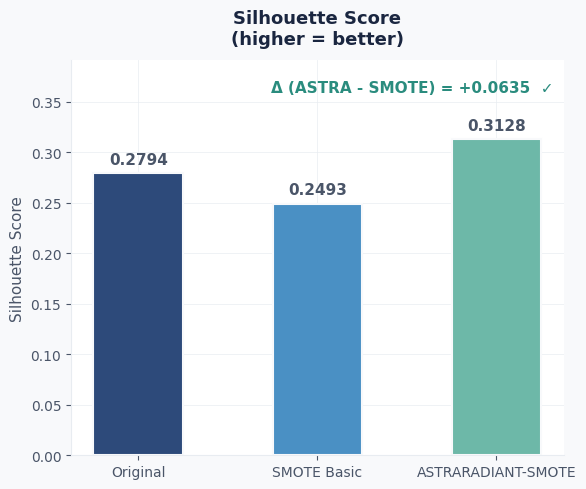

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/cluster_metric_mean_inter_dist_astraradiant_smote.png


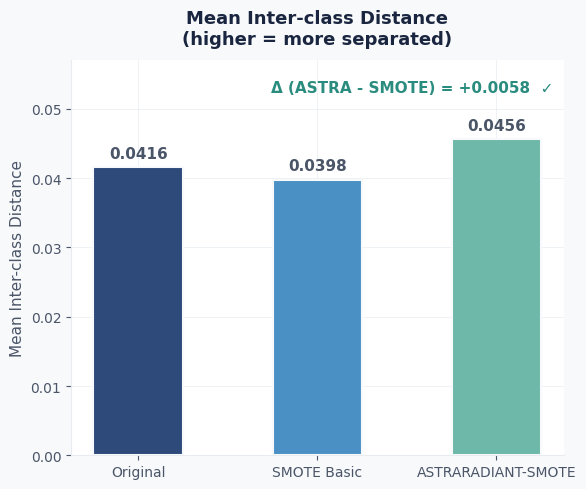

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/cluster_metric_mean_intra_dist_astraradiant_smote.png


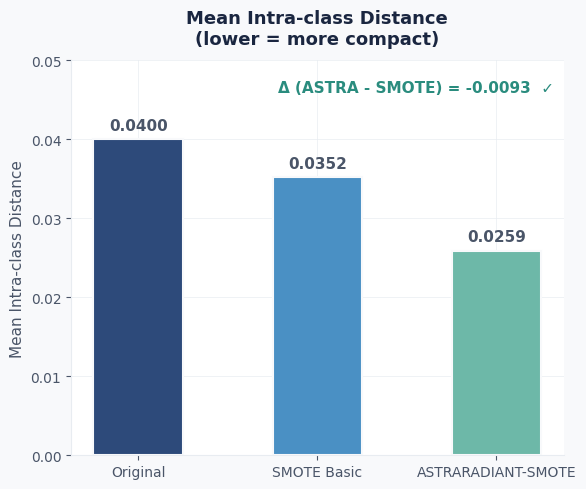

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/cluster_metric_cluster_overlap_astraradiant_smote.png


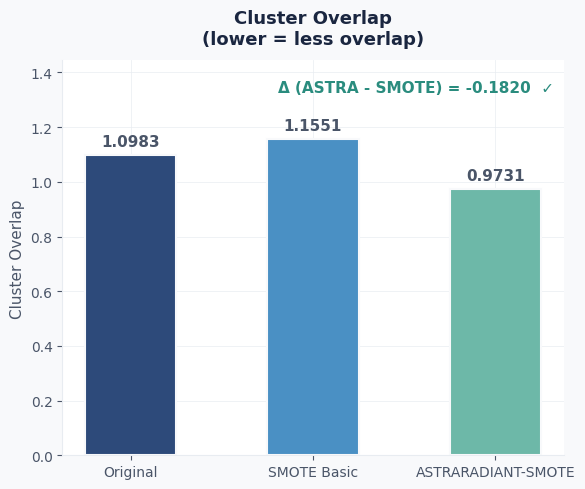

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/cluster_metric_davies_bouldin_astraradiant_smote.png


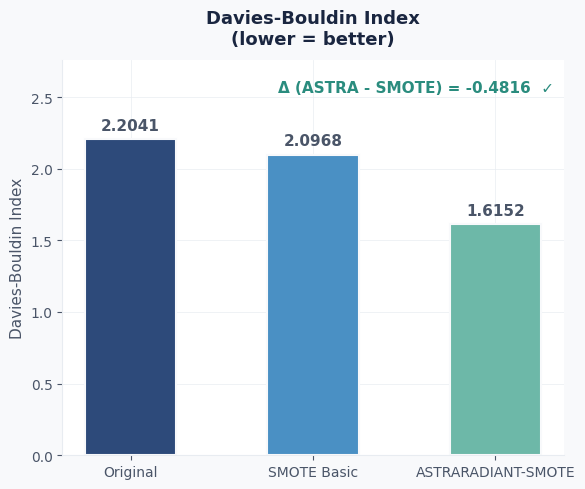

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/cluster_metric_calinski_harabasz_astraradiant_smote.png


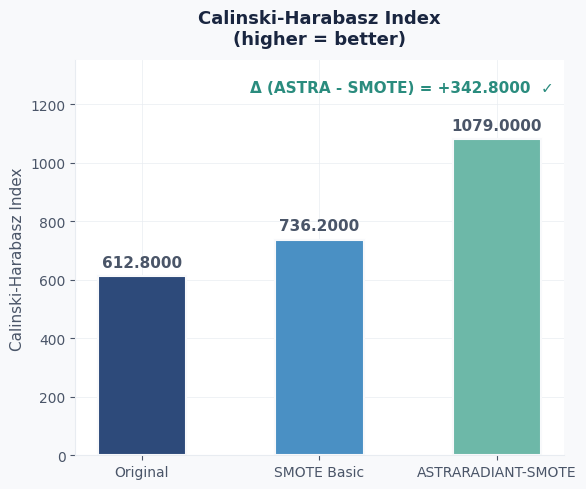

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/cluster_intra_comparison_astraradiant_smote.png


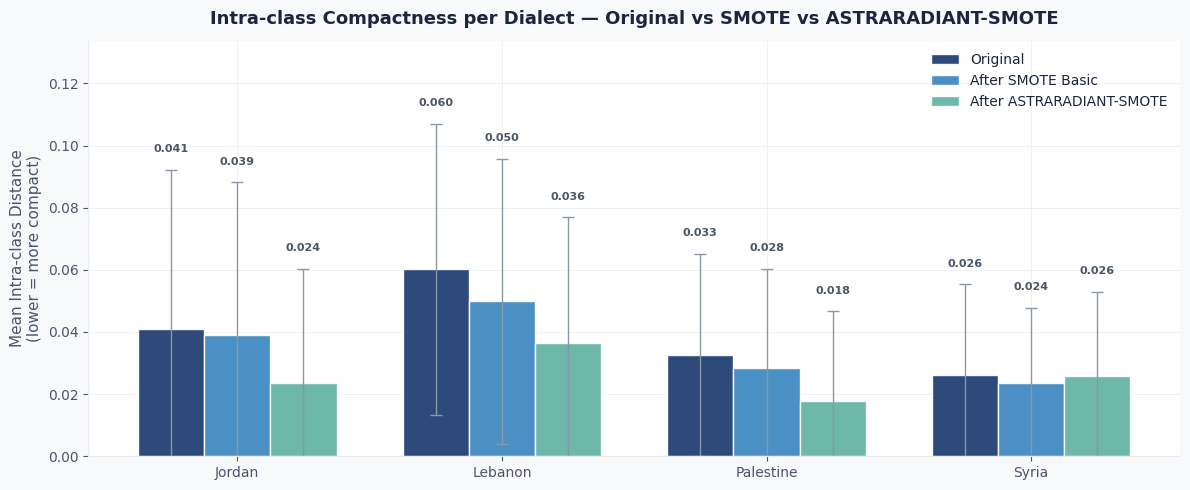


✅ Semua cluster metric plots (Original vs SMOTE vs ASTRARADIANT-SMOTE) tersimpan!


In [29]:
# Pastikan sudah import dari utils_ml
from utils_ml import plot_cluster_metrics_comparison, plot_intra_class_compactness

# ── Visualisasi perbandingan metrik — MASING-MASING ──────────
plot_cluster_metrics_comparison(mb, ms, ma, proposed_name="ASTRARADIANT-SMOTE", dir=IMAGE_DIR, name="cluster_metrics_comparison")

# ── Intra per class — before vs SMOTE vs after ───────────────
plot_intra_class_compactness(mb, ms, ma, label_names, proposed_name="ASTRARADIANT-SMOTE", dir=IMAGE_DIR, name="intra_class_compactness")

print("\n✅ Semua cluster metric plots (Original vs SMOTE vs ASTRARADIANT-SMOTE) tersimpan!")

## Modeling

### Final Model Training

In [19]:
model = lgb.LGBMClassifier(
    objective="multiclass", num_class=len(label_names),
    n_estimators=10000, learning_rate=0.01,
    max_depth=7, min_child_weight=1e-3,
    subsample=0.75, subsample_freq=1,
    random_state=42, n_jobs=-1, force_col_wise=True, verbose=-1,
    **best_params
)
print("Training model...")
model.fit(
    Xtr_os, ytr_os,
    eval_set=[(Xtr_os, ytr_os), (Xval_sel, y_val)],
    eval_metric="multi_logloss",
    callbacks=[
        lgb.early_stopping(stopping_rounds=150, min_delta=1e-4),
        lgb.log_evaluation(100),
    ]
)
print("Best iteration:", model.best_iteration_)

Training model...
Training until validation scores don't improve for 150 rounds
[100]	training's multi_logloss: 0.402626	valid_1's multi_logloss: 0.470954
[200]	training's multi_logloss: 0.237056	valid_1's multi_logloss: 0.344902
[300]	training's multi_logloss: 0.190692	valid_1's multi_logloss: 0.318573
[400]	training's multi_logloss: 0.1696	valid_1's multi_logloss: 0.310962
[500]	training's multi_logloss: 0.15522	valid_1's multi_logloss: 0.307384
[600]	training's multi_logloss: 0.143478	valid_1's multi_logloss: 0.305258
[700]	training's multi_logloss: 0.133473	valid_1's multi_logloss: 0.303347
[800]	training's multi_logloss: 0.124676	valid_1's multi_logloss: 0.302216
[900]	training's multi_logloss: 0.117326	valid_1's multi_logloss: 0.301526
[1000]	training's multi_logloss: 0.110457	valid_1's multi_logloss: 0.300937
[1100]	training's multi_logloss: 0.10427	valid_1's multi_logloss: 0.300391
[1200]	training's multi_logloss: 0.098591	valid_1's multi_logloss: 0.300267
[1300]	training's mul

✅ History learning curve berhasil disimpan ke: artifacts/lightgbm_astra_radiant/docs/lightgbm_astra_radiant_learning_curve_history.csv
🖼️ Saved: artifacts/lightgbm_astra_radiant/image/learning_curve_loss.png


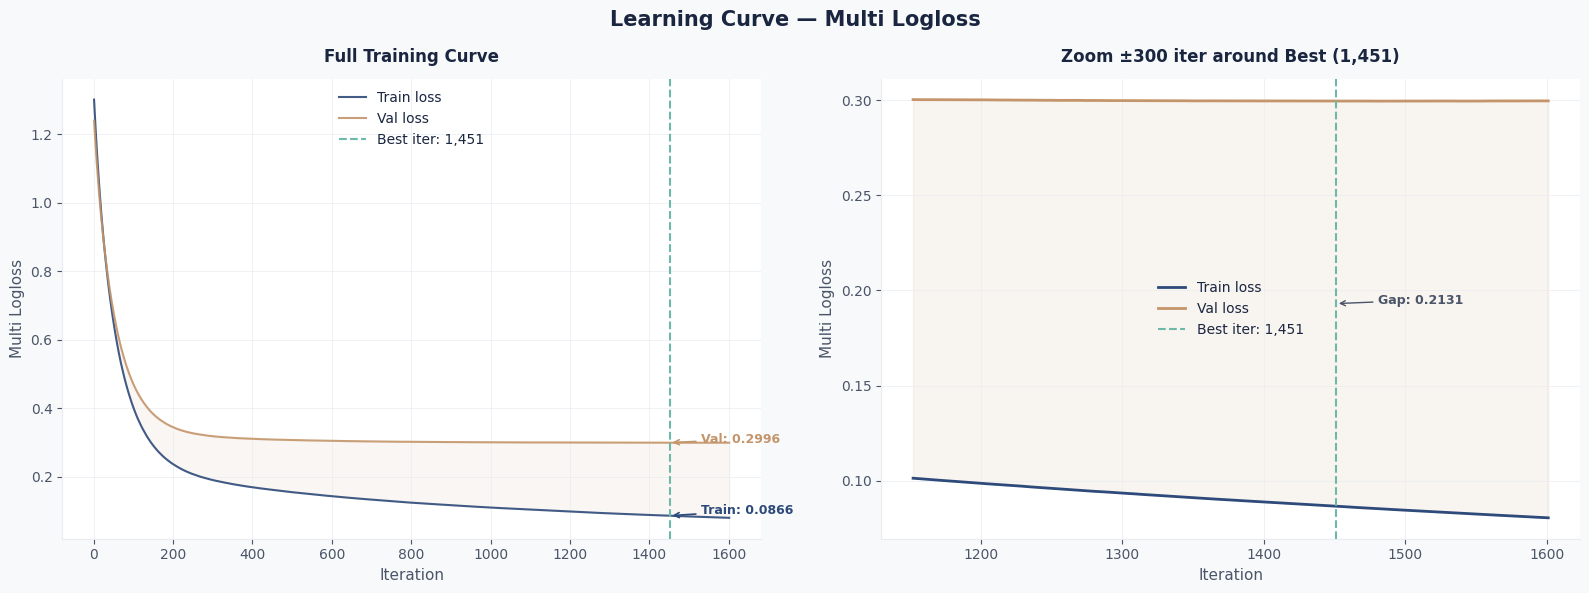

In [20]:
# ── Learning Curve ───────────────────────────────────────────
results  = model.evals_result_
train_loss = results['training']['multi_logloss']
val_loss   = results['valid_1']['multi_logloss']
iterations = range(1, len(train_loss) + 1)
best_iter  = model.best_iteration_

history_df = pd.DataFrame({
    'Iteration': iterations,
    'Train_Multi_Logloss': train_loss,
    'Val_Multi_Logloss': val_loss
})

# Tambahkan penanda (flag) khusus untuk iterasi terbaik
history_df['Is_Best_Iteration'] = history_df['Iteration'] == best_iter

# Simpan ke CSV (menggunakan variabel DOCS_DIR dan KOMPOSISI dari kodemu sebelumnya)
csv_path = os.path.join(DOCS_DIR, f"{KOMPOSISI}_learning_curve_history.csv")
history_df.to_csv(csv_path, index=False)

print(f"✅ History learning curve berhasil disimpan ke: {csv_path}")

fig, axes = plt.subplots(1, 2, figsize=(16, 6), facecolor=BG_COLOR)
fig.suptitle("Learning Curve — Multi Logloss",
             fontsize=15, fontweight='bold', color=TEXT_DARK)

# ── Kiri: full curve ─────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(CARD_COLOR)

ax.plot(iterations, train_loss,
        color="#2D4A7A", linewidth=1.5,
        label="Train loss", alpha=0.9)
ax.plot(iterations, val_loss,
        color="#C4956A", linewidth=1.5,
        label="Val loss", alpha=0.9)

# shading gap antara train dan val
ax.fill_between(iterations, train_loss, val_loss,
                alpha=0.08, color="#C4956A")

# best iteration line
ax.axvline(best_iter, color="#6DB8A8", linewidth=1.5,
           linestyle="--", label=f"Best iter: {best_iter:,}")

# annotasi nilai loss di best iter
ax.annotate(
    f"Val: {val_loss[best_iter-1]:.4f}",
    xy=(best_iter, val_loss[best_iter-1]),
    xytext=(best_iter + len(iterations)*0.05, val_loss[best_iter-1]),
    fontsize=9, color="#C4956A", fontweight='bold',
    arrowprops=dict(arrowstyle='->', color="#C4956A", lw=1.2),
)
ax.annotate(
    f"Train: {train_loss[best_iter-1]:.4f}",
    xy=(best_iter, train_loss[best_iter-1]),
    xytext=(best_iter + len(iterations)*0.05, train_loss[best_iter-1]*1.05),
    fontsize=9, color="#2D4A7A", fontweight='bold',
    arrowprops=dict(arrowstyle='->', color="#2D4A7A", lw=1.2),
)

ax.set_xlabel("Iteration",       fontsize=11, color=TEXT_MID)
ax.set_ylabel("Multi Logloss",   fontsize=11, color=TEXT_MID)
ax.set_title("Full Training Curve", fontsize=12,
             fontweight='bold', color=TEXT_DARK)
ax.legend(frameon=False, fontsize=10)
ax.grid(color=GRID_COLOR, linewidth=0.6)
ax.spines[['top','right']].set_visible(False)

# ── Kanan: zoom di sekitar best iteration ────────────────────
ax2 = axes[1]
ax2.set_facecolor(CARD_COLOR)

zoom_start = max(0, best_iter - 300)
zoom_end   = min(len(train_loss), best_iter + 300)
iters_zoom = range(zoom_start + 1, zoom_end + 1)

ax2.plot(iters_zoom, train_loss[zoom_start:zoom_end],
         color="#2D4A7A", linewidth=2, label="Train loss")
ax2.plot(iters_zoom, val_loss[zoom_start:zoom_end],
         color="#C4956A", linewidth=2, label="Val loss")
ax2.fill_between(iters_zoom,
                 train_loss[zoom_start:zoom_end],
                 val_loss[zoom_start:zoom_end],
                 alpha=0.1, color="#C4956A")
ax2.axvline(best_iter, color="#6DB8A8", linewidth=1.5,
            linestyle="--", label=f"Best iter: {best_iter:,}")

# gap label
gap = val_loss[best_iter-1] - train_loss[best_iter-1]
ax2.annotate(
    f"Gap: {gap:.4f}",
    xy=(best_iter, (val_loss[best_iter-1] + train_loss[best_iter-1]) / 2),
    xytext=(best_iter + 30, (val_loss[best_iter-1] + train_loss[best_iter-1]) / 2),
    fontsize=9, color=TEXT_MID, fontweight='bold',
    arrowprops=dict(arrowstyle='->', color=TEXT_MID, lw=1.0),
)

ax2.set_xlabel("Iteration",     fontsize=11, color=TEXT_MID)
ax2.set_ylabel("Multi Logloss", fontsize=11, color=TEXT_MID)
ax2.set_title(f"Zoom ±300 iter around Best ({best_iter:,})",
              fontsize=12, fontweight='bold', color=TEXT_DARK)
ax2.legend(frameon=False, fontsize=10)
ax2.grid(color=GRID_COLOR, linewidth=0.6)
ax2.spines[['top','right']].set_visible(False)

fig.tight_layout()
save_and_show("learning_curve_loss")

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/learning_curve_full.png


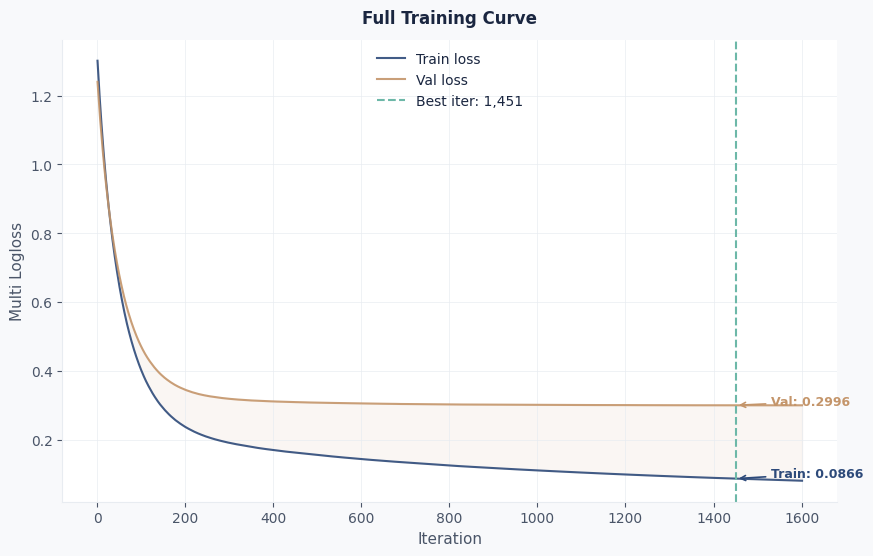

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/learning_curve_zoom.png


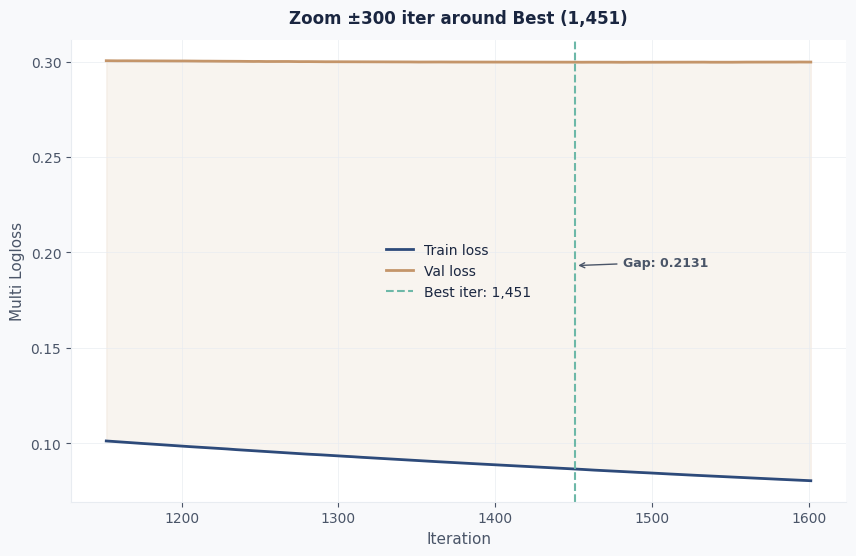


=== LEARNING CURVE SUMMARY ===
Total iterations trained : 1,601
Best iteration           : 1,451
Train loss @ best        : 0.0866
Val   loss @ best        : 0.2996
Gap (val - train)        : 0.2131
Early stop saved iters   : 150


In [21]:
# ── Learning Curve ───────────────────────────────────────────
plt.figure(figsize=(10, 6), facecolor=BG_COLOR)
ax = plt.gca()
ax.set_facecolor(CARD_COLOR)

plt.plot(iterations, train_loss,
         color="#2D4A7A", linewidth=1.5,
         label="Train loss", alpha=0.9)
plt.plot(iterations, val_loss,
         color="#C4956A", linewidth=1.5,
         label="Val loss", alpha=0.9)

plt.fill_between(iterations, train_loss, val_loss,
                 alpha=0.08, color="#C4956A")

plt.axvline(best_iter, color="#6DB8A8", linewidth=1.5,
            linestyle="--", label=f"Best iter: {best_iter:,}")

# annotasi
plt.annotate(
    f"Val: {val_loss[best_iter-1]:.4f}",
    xy=(best_iter, val_loss[best_iter-1]),
    xytext=(best_iter + len(iterations)*0.05, val_loss[best_iter-1]),
    fontsize=9, color="#C4956A", fontweight='bold',
    arrowprops=dict(arrowstyle='->', color="#C4956A", lw=1.2),
)
plt.annotate(
    f"Train: {train_loss[best_iter-1]:.4f}",
    xy=(best_iter, train_loss[best_iter-1]),
    xytext=(best_iter + len(iterations)*0.05, train_loss[best_iter-1]*1.05),
    fontsize=9, color="#2D4A7A", fontweight='bold',
    arrowprops=dict(arrowstyle='->', color="#2D4A7A", lw=1.2),
)

plt.xlabel("Iteration", fontsize=11, color=TEXT_MID)
plt.ylabel("Multi Logloss", fontsize=11, color=TEXT_MID)
plt.title("Full Training Curve", fontsize=12,
          fontweight='bold', color=TEXT_DARK)

plt.legend(frameon=False)
plt.grid(color=GRID_COLOR, linewidth=0.6)
ax.spines[['top','right']].set_visible(False)

save_and_show("learning_curve_full")

plt.figure(figsize=(10, 6), facecolor=BG_COLOR)
ax = plt.gca()
ax.set_facecolor(CARD_COLOR)

zoom_start = max(0, best_iter - 300)
zoom_end   = min(len(train_loss), best_iter + 300)
iters_zoom = range(zoom_start + 1, zoom_end + 1)

plt.plot(iters_zoom, train_loss[zoom_start:zoom_end],
         color="#2D4A7A", linewidth=2, label="Train loss")
plt.plot(iters_zoom, val_loss[zoom_start:zoom_end],
         color="#C4956A", linewidth=2, label="Val loss")

plt.fill_between(iters_zoom,
                 train_loss[zoom_start:zoom_end],
                 val_loss[zoom_start:zoom_end],
                 alpha=0.1, color="#C4956A")

plt.axvline(best_iter, color="#6DB8A8", linewidth=1.5,
            linestyle="--", label=f"Best iter: {best_iter:,}")

# gap annotation
gap = val_loss[best_iter-1] - train_loss[best_iter-1]
plt.annotate(
    f"Gap: {gap:.4f}",
    xy=(best_iter, (val_loss[best_iter-1] + train_loss[best_iter-1]) / 2),
    xytext=(best_iter + 30, (val_loss[best_iter-1] + train_loss[best_iter-1]) / 2),
    fontsize=9, color=TEXT_MID, fontweight='bold',
    arrowprops=dict(arrowstyle='->', color=TEXT_MID, lw=1.0),
)

plt.xlabel("Iteration", fontsize=11, color=TEXT_MID)
plt.ylabel("Multi Logloss", fontsize=11, color=TEXT_MID)
plt.title(f"Zoom ±300 iter around Best ({best_iter:,})",
          fontsize=12, fontweight='bold', color=TEXT_DARK)

plt.legend(frameon=False)
plt.grid(color=GRID_COLOR, linewidth=0.6)
ax.spines[['top','right']].set_visible(False)

save_and_show("learning_curve_zoom")

# ── Summary stats ────────────────────────────────────────────
print(f"\n=== LEARNING CURVE SUMMARY ===")
print(f"Total iterations trained : {len(train_loss):,}")
print(f"Best iteration           : {best_iter:,}")
print(f"Train loss @ best        : {train_loss[best_iter-1]:.4f}")
print(f"Val   loss @ best        : {val_loss[best_iter-1]:.4f}")
print(f"Gap (val - train)        : {val_loss[best_iter-1] - train_loss[best_iter-1]:.4f}")
print(f"Early stop saved iters   : {len(train_loss) - best_iter:,}")

## Save Artifacts

In [22]:
print("💾 Menyimpan artifacts modeling...")

joblib.dump(model, os.path.join(MODEL_DIR, f"model_{KOMPOSISI}.pkl"))

print("✅ Artifacts modeling berhasil disimpan!")

💾 Menyimpan artifacts modeling...
✅ Artifacts modeling berhasil disimpan!


## Evaluation & Analysis

### Evaluation Report

In [23]:
def evaluate_split(name, y_true, y_pred):
    print(f"\n===== {name} =====")
    print("Accuracy :", accuracy_score(y_true, y_pred))
    print("Macro F1 :", f1_score(y_true, y_pred, average="macro"))
    print(classification_report(y_true, y_pred, target_names=label_names, digits=4))

for split_name, X_sp, y_sp in [
    ("TRAIN", Xtr_os, ytr_os),
    ("VAL",   Xval_sel, y_val),
    ("TEST",  Xte_sel,  y_test),
]:
    evaluate_split(split_name, y_sp,
                   model.predict(X_sp, num_iteration=model.best_iteration_))

cm    = confusion_matrix(y_test, model.predict(Xte_sel, num_iteration=model.best_iteration_))
cm_df = pd.DataFrame(cm, index=label_names, columns=label_names)
print("\nConfusion Matrix:\n", cm_df)


===== TRAIN =====
Accuracy : 0.9738656380975521
Macro F1 : 0.9705806429878359
              precision    recall  f1-score   support

      Jordan     0.9669    0.9404    0.9535      7746
     Lebanon     0.9728    0.9763    0.9746     17905
   Palestine     0.9772    0.9728    0.9750     17546
       Syria     0.9744    0.9842    0.9793     22655

    accuracy                         0.9739     65852
   macro avg     0.9728    0.9684    0.9706     65852
weighted avg     0.9738    0.9739    0.9738     65852


===== VAL =====
Accuracy : 0.8970514239710174
Macro F1 : 0.8515822448491368
              precision    recall  f1-score   support

      Jordan     0.8232    0.7293    0.7734      1053
     Lebanon     0.8446    0.8504    0.8475      1624
   Palestine     0.8313    0.8396    0.8354      1596
       Syria     0.9423    0.9578    0.9500      5664

    accuracy                         0.8971      9937
   macro avg     0.8603    0.8443    0.8516      9937
weighted avg     0.8959    0.

### Confusion matrix heatmap

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/confusion_matrix.png


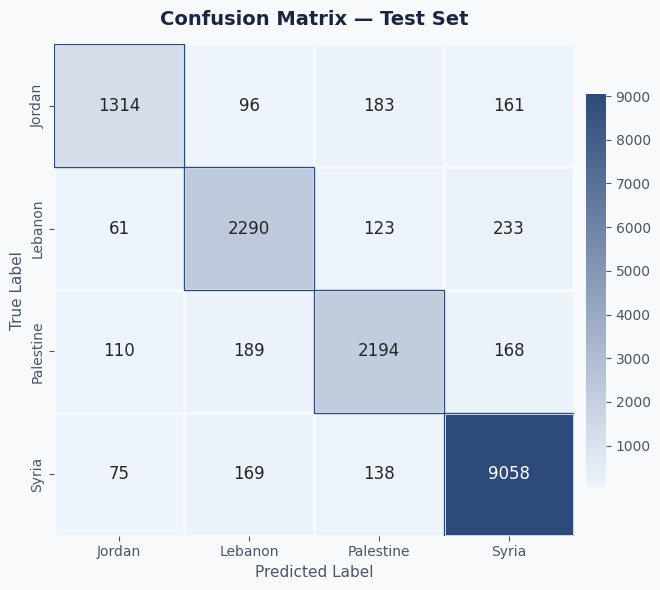


=== SUMMARY ===
Train F1 : 0.9706
Val F1   : 0.8516
Test F1  : 0.8529
Gap T-V  : 0.1190  ⚠ overfit
Gap V-Te : 0.0014  ✓ generalize baik


In [24]:
from matplotlib.colors import LinearSegmentedColormap

# ── 2. Confusion Matrix ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6), facecolor=BG_COLOR)

cmap = LinearSegmentedColormap.from_list(
    "custom_blue", ["#EEF4FB", "#2D4A7A"], N=256)

sns.heatmap(
    cm_df, annot=True, fmt='d', cmap=cmap,
    linewidths=2, linecolor=BG_COLOR,
    annot_kws={"size": 12},
    ax=ax, cbar_kws={"shrink": 0.8, "pad": 0.02}
)

ax.grid(False)

# Highlight diagonal
for i in range(len(cm_df)):
    ax.add_patch(plt.Rectangle((i, i), 1, 1,
                 fill=False, edgecolor="#2D4A7A", lw=1))

ax.set_title("Confusion Matrix — Test Set",
             fontsize=14, fontweight='bold', color=TEXT_DARK, pad=14)
ax.set_ylabel("True Label",     fontsize=11, color=TEXT_MID)
ax.set_xlabel("Predicted Label", fontsize=11, color=TEXT_MID)
ax.tick_params(axis='both', labelsize=10)
ax.figure.facecolor = BG_COLOR

fig.tight_layout()
save_and_show("confusion_matrix")


f1_tr  = f1_score(ytr_os, model.predict(Xtr_os,  num_iteration=model.best_iteration_), average="macro")
f1_val = f1_score(y_val,   model.predict(Xval_sel, num_iteration=model.best_iteration_), average="macro")
f1_te  = f1_score(y_test,  model.predict(Xte_sel,  num_iteration=model.best_iteration_), average="macro")
print(f"\n=== SUMMARY ===")
print(f"Train F1 : {f1_tr:.4f}")
print(f"Val F1   : {f1_val:.4f}")
print(f"Test F1  : {f1_te:.4f}")
print(f"Gap T-V  : {f1_tr - f1_val:.4f}  {'⚠ overfit' if f1_tr - f1_val > 0.10 else '✓ ok'}")
print(f"Gap V-Te : {abs(f1_val - f1_te):.4f}  {'✓ generalize baik' if abs(f1_val - f1_te) < 0.01 else '△ cek'}")

### Feature Importance per Block

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/feature_importance_total.png


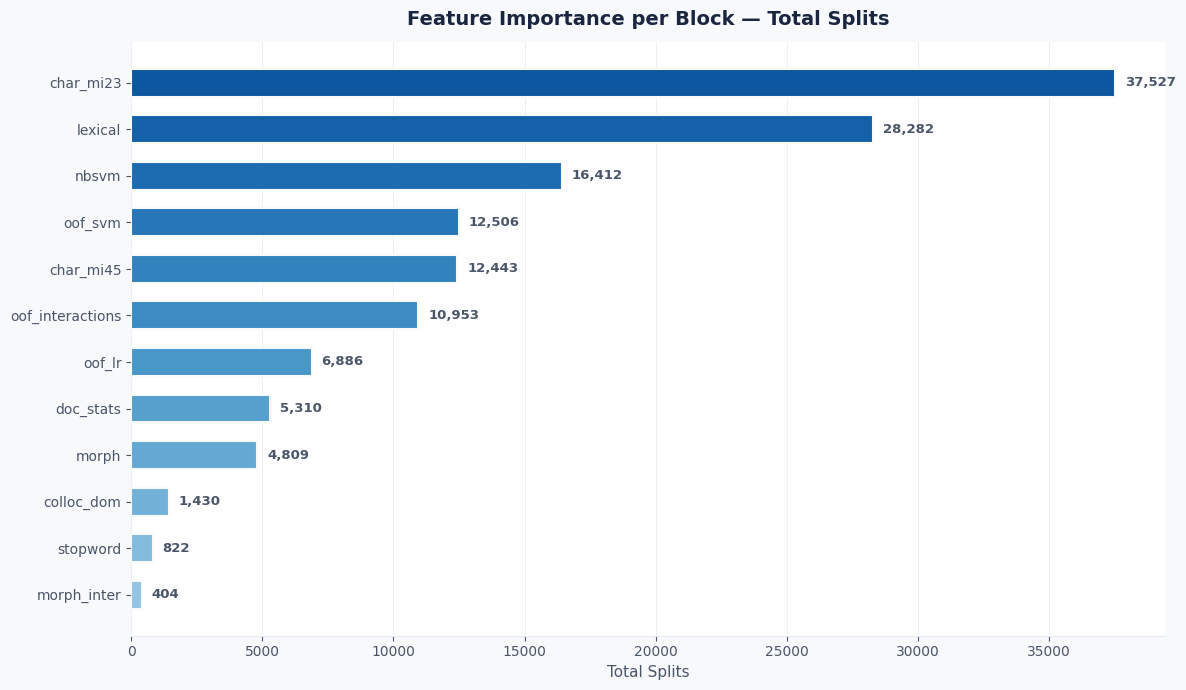

   Feature_Block  Total_Importance  Average_Importance_per_Col  Cols
       char_mi23             37527                   75.054000   500
         lexical             28282                   11.686777  2420
           nbsvm             16412                 4103.000000     4
         oof_svm             12506                 1563.250000     8
       char_mi45             12443                    4.695472  2650
oof_interactions             10953                 1095.300000    10
          oof_lr              6886                  860.750000     8
       doc_stats              5310                  758.571429     7
           morph              4809                  184.961538    26
      colloc_dom              1430                 1430.000000     1
        stopword               822                  411.000000     2
     morph_inter               404                   50.500000     8


In [25]:
importances  = model.feature_importances_
block_slices_imp = build_block_slices(feat.block_sizes)

block_importance = {}
for name, (s, e) in block_slices_imp.items():
    if name in drop_list or s >= len(importances):
        continue
    end_idx  = min(e, len(importances))
    blk_imp  = importances[s:end_idx]
    if len(blk_imp) == 0:
        continue
    block_importance[name] = {
        'Total_Importance'          : blk_imp.sum(),
        'Average_Importance_per_Col': blk_imp.mean(),
        'Cols'                      : len(blk_imp),
    }

df_imp = (
    pd.DataFrame.from_dict(block_importance, orient='index')
      .reset_index().rename(columns={'index': 'Feature_Block'})
      .sort_values('Total_Importance', ascending=False)
)

fig, ax = plt.subplots(figsize=(12, 7), facecolor=BG_COLOR)
ax.set_facecolor(CARD_COLOR)

n      = len(df_imp)
colors = plt.cm.Blues(np.linspace(0.4, 0.85, n))[::-1]

bars = ax.barh(df_imp['Feature_Block'], df_imp['Total_Importance'],
               color=colors, edgecolor=BG_COLOR, linewidth=1.5, height=0.6)

# Value labels
for bar, val in zip(bars, df_imp['Total_Importance']):
    ax.text(bar.get_width() + df_imp['Total_Importance'].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{int(val):,}", va='center', ha='left',
            fontsize=9.5, color=TEXT_MID, fontweight='bold')

ax.set_xlabel("Total Splits", fontsize=11, color=TEXT_MID)
ax.set_ylabel("")
ax.set_title("Feature Importance per Block — Total Splits",
             fontsize=14, fontweight='bold', color=TEXT_DARK)
ax.xaxis.grid(True, color=GRID_COLOR, linewidth=0.8)
ax.yaxis.grid(False)
ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)

ax.invert_yaxis()

fig.tight_layout()
save_and_show("feature_importance_total")

print(df_imp.to_string(index=False))

### Average importance per column

🖼️ Saved: artifacts/lightgbm_astra_radiant/image/feature_importance_avg.png


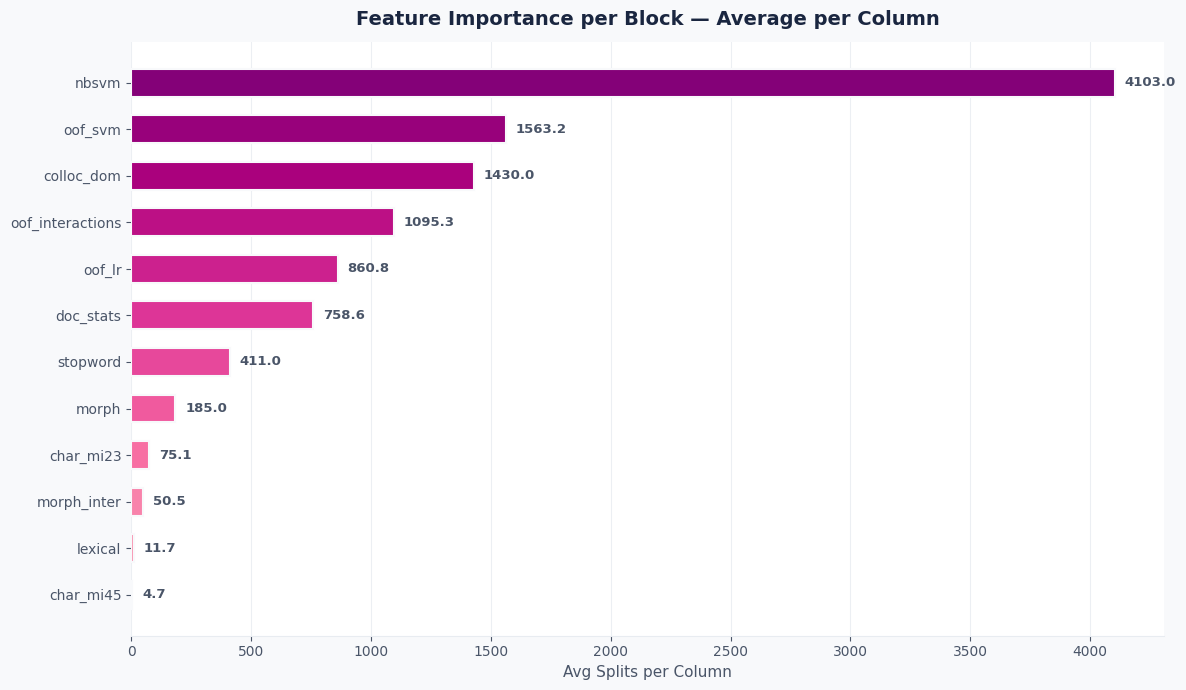

In [26]:
df_imp_avg = df_imp.sort_values('Average_Importance_per_Col', ascending=False)

fig, ax = plt.subplots(figsize=(12, 7), facecolor=BG_COLOR)
ax.set_facecolor(CARD_COLOR)

n      = len(df_imp_avg)
colors = plt.cm.RdPu(np.linspace(0.35, 0.85, n))[::-1]

bars = ax.barh(df_imp_avg['Feature_Block'],
               df_imp_avg['Average_Importance_per_Col'],
               color=colors, edgecolor=BG_COLOR, linewidth=1.5, height=0.6)

for bar, val in zip(bars, df_imp_avg['Average_Importance_per_Col']):
    ax.text(bar.get_width() + df_imp_avg['Average_Importance_per_Col'].max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}", va='center', ha='left',
            fontsize=9.5, color=TEXT_MID, fontweight='bold')

ax.set_xlabel("Avg Splits per Column", fontsize=11, color=TEXT_MID)
ax.set_ylabel("")
ax.set_title("Feature Importance per Block — Average per Column",
             fontsize=14, fontweight='bold', color=TEXT_DARK)
ax.xaxis.grid(True, color=GRID_COLOR, linewidth=0.8)
ax.yaxis.grid(False)
ax.set_axisbelow(True)
ax.spines['left'].set_visible(False)

ax.invert_yaxis()

fig.tight_layout()
save_and_show("feature_importance_avg")

### Clustering Analysis

In [30]:
from sklearn.neighbors import NearestNeighbors

def synthetic_quality_analysis(X_orig, X_synth, y_orig, y_synth,
                                 label_names, method_name):
    """
    Bandingkan distribusi jarak NN antara:
    - sampel asli ke tetangga aslinya
    - sampel sintetis ke tetangga aslinya
    Semakin mirip distribusinya, semakin realistis synthetic samples.
    """
    results = {}
    classes = np.unique(y_orig)

    for c in classes:
        cls_name  = label_names[c]
        idx_orig  = np.where(y_orig  == c)[0]
        idx_synth = np.where(y_synth == c)[0]

        if len(idx_synth) == 0:
            continue

        X_c_orig  = X_orig[idx_orig]
        X_c_synth = X_synth[idx_synth]

        if issparse(X_c_orig):
            X_c_orig  = X_c_orig.toarray()
            X_c_synth = X_c_synth.toarray()

        # fit NN di sampel asli
        k   = min(5, len(idx_orig) - 1)
        nn  = NearestNeighbors(n_neighbors=k+1, metric='cosine',
                               algorithm='brute')
        nn.fit(X_c_orig)

        # jarak sampel asli ke NN-nya (distribusi referensi)
        dist_orig, _  = nn.kneighbors(X_c_orig)
        dist_orig     = dist_orig[:, 1:].mean(axis=1)  # buang self

        # jarak sampel sintetis ke NN asli
        # subsample sintetis kalau terlalu banyak
        n_syn = min(len(idx_synth), 2000)
        rng   = np.random.default_rng(42)
        s_idx = rng.choice(len(idx_synth), n_syn, replace=False)
        dist_synth, _ = nn.kneighbors(X_c_synth[s_idx])
        dist_synth    = dist_synth[:, 0:].mean(axis=1)

        results[cls_name] = {
            "orig_mean"  : float(np.mean(dist_orig)),
            "orig_std"   : float(np.std(dist_orig)),
            "synth_mean" : float(np.mean(dist_synth)),
            "synth_std"  : float(np.std(dist_synth)),
            "ratio"      : float(np.mean(dist_synth) / (np.mean(dist_orig) + 1e-9)),
            # ratio mendekati 1.0 = sampel sintetis "sebidang" dengan asli
            # ratio >> 1.0 = sampel sintetis terlalu jauh (noise)
            # ratio << 1.0 = sampel sintetis terlalu dekat (duplikasi)
        }

    return results


def inter_class_intrusion(X_os, y_os, y_orig, label_names, method_name):
    """
    Hitung berapa persen sampel sintetis kelas A yang
    lebih dekat ke centroid kelas lain (intrusi).
    Semakin rendah = semakin bersih.
    """
    # identifikasi mana yang sintetis
    n_orig   = len(y_orig)
    y_synth  = y_os[n_orig:]
    X_synth  = X_os[n_orig:]
    classes  = np.unique(y_orig)

    if issparse(X_os):
        X_arr = X_os.toarray()
    else:
        X_arr = np.asarray(X_os)

    Xn = normalize(X_arr, norm="l2")

    # centroid per kelas dari data ASLI saja
    centroids = {}
    for c in classes:
        idx = np.where(y_orig == c)[0]
        mu  = Xn[idx].mean(axis=0)
        centroids[c] = mu / (np.linalg.norm(mu) + 1e-9)

    if issparse(X_synth):
        X_synth_arr = X_synth.toarray()
    else:
        X_synth_arr = np.asarray(X_synth)

    Xsn = normalize(X_synth_arr, norm="l2")

    intrusion_per_class = {}
    for c in classes:
        idx_c = np.where(y_synth == c)[0]
        if len(idx_c) == 0:
            continue
        Xsc = Xsn[idx_c]

        # cosine similarity ke semua centroid
        sims = np.array([Xsc @ centroids[cc] for cc in classes]).T
        pred = np.argmax(sims, axis=1)  # kelas terdekat

        correct  = np.sum(pred == list(classes).index(c))
        intruded = len(idx_c) - correct
        intrusion_per_class[label_names[c]] = {
            "n_synth"       : len(idx_c),
            "n_intruded"    : int(intruded),
            "intrusion_rate": round(intruded / len(idx_c), 4),
        }

    return intrusion_per_class

def decision_boundary_analysis_3way(model_orig, model_smote, model_knsmote,
                                    Xte_sel, y_test, label_names):
    """
    Bandingkan Decision Boundary dari 3 Model:
    Original -> SMOTE -> KNSMOTE
    """
    proba_orig    = model_orig.predict_proba(Xte_sel, num_iteration=model_orig.best_iteration_)
    proba_smote   = model_smote.predict_proba(Xte_sel, num_iteration=model_smote.best_iteration_)
    proba_knsmote = model_knsmote.predict_proba(Xte_sel, num_iteration=model_knsmote.best_iteration_)

    results = {}
    for i, cls_name in enumerate(label_names):
        mask = y_test == i

        # Confidence untuk kelas yang benar
        conf_o = proba_orig[mask, i]
        conf_s = proba_smote[mask, i]
        conf_k = proba_knsmote[mask, i]

        # Fungsi helper untuk menghitung Margin (Selisih probabilitas tebakan ke-1 dan ke-2)
        def get_margin(p):
            srt = np.sort(p, axis=1)
            return srt[:, -1] - srt[:, -2]

        margin_o = get_margin(proba_orig[mask])
        margin_s = get_margin(proba_smote[mask])
        margin_k = get_margin(proba_knsmote[mask])

        # Fungsi helper untuk menghitung Entropy (Kebingungan)
        def get_entropy(p):
            return -(p * np.log(p + 1e-9)).sum(axis=1)

        entropy_o = get_entropy(proba_orig[mask])
        entropy_s = get_entropy(proba_smote[mask])
        entropy_k = get_entropy(proba_knsmote[mask])

        results[cls_name] = {
            "conf_orig"    : round(float(conf_o.mean()), 4),
            "conf_smote"   : round(float(conf_s.mean()), 4),
            "conf_knsmote" : round(float(conf_k.mean()), 4),
            "conf_delta"   : round(float(conf_k.mean() - conf_o.mean()), 4), # KNS vs Orig

            "margin_orig"   : round(float(margin_o.mean()), 4),
            "margin_smote"  : round(float(margin_s.mean()), 4),
            "margin_knsmote": round(float(margin_k.mean()), 4),
            "margin_delta"  : round(float(margin_k.mean() - margin_o.mean()), 4),

            "entropy_orig"   : round(float(entropy_o.mean()), 4),
            "entropy_smote"  : round(float(entropy_s.mean()), 4),
            "entropy_knsmote": round(float(entropy_k.mean()), 4),
            "entropy_delta"  : round(float(entropy_k.mean() - entropy_o.mean()), 4),
        }

    return results

In [31]:
# Pastikan variabel Xtr_smote dan ytr_smote sudah ada di memory (dari cell sebelumnya)
n_orig = len(y_train)

# Ekstrak data sintetis SMOTE
X_synth_smote = Xtr_smote[n_orig:]
y_synth_smote = ytr_smote[n_orig:]

# Ekstrak data sintetis KNSMOTE (asumsi variabel KNSMOTE-mu bernama Xtr_os)
X_synth_kns = Xtr_os[n_orig:]
y_synth_kns = ytr_os[n_orig:]

print("\n" + "=".center(85, "="))
print(" 1. SYNTHETIC QUALITY ANALYSIS (SMOTE vs KNSMOTE) ".center(85, "="))
print("=".center(85, "="))

# Hitung untuk keduanya
quality_smote = synthetic_quality_analysis(Xtr_sel, X_synth_smote, y_train, y_synth_smote, label_names, "SMOTE")
quality_kns   = synthetic_quality_analysis(Xtr_sel, X_synth_kns, y_train, y_synth_kns, label_names, "KNSMOTE")

for cls in quality_smote.keys():
    res_s = quality_smote[cls]
    res_k = quality_kns.get(cls, res_s) # Fallback kalau kosong

    # Delta KNS vs SMOTE (Mendekati 1.0 itu lebih baik)
    dist_to_1_smote = abs(1.0 - res_s['ratio'])
    dist_to_1_kns = abs(1.0 - res_k['ratio'])
    is_better = dist_to_1_kns < dist_to_1_smote

    print(f"💠 Dialect: {cls}")
    print(f"   - Quality Ratio SMOTE   : {res_s['ratio']:.4f}")
    print(f"   - Quality Ratio KNSMOTE : {res_k['ratio']:.4f} {'(✅ Lebih Mendekati 1.0)' if is_better else '(⚠️ Kurang dari SMOTE)'}")
    print(f"     [Target Ideal = 1.0 | Realistis jika 0.8 - 1.2]\n")


print("=".center(85, "="))
print(" 2. INTER-CLASS INTRUSION ANALYSIS (SMOTE vs KNSMOTE) ".center(85, "="))
print("=".center(85, "="))

# Hitung untuk keduanya
intrusion_smote = inter_class_intrusion(Xtr_smote, ytr_smote, y_train, label_names, "SMOTE")
intrusion_kns   = inter_class_intrusion(Xtr_os, ytr_os, y_train, label_names, "KNSMOTE")

for cls in intrusion_smote.keys():
    res_s = intrusion_smote[cls]
    res_k = intrusion_kns.get(cls, res_s)

    delta_intr = res_k['intrusion_rate'] - res_s['intrusion_rate']
    is_cleaner = delta_intr < 0 # Intrusion lebih kecil = lebih baik

    print(f"💠 Dialect: {cls}")
    print(f"   - Intrusion SMOTE       : {res_s['intrusion_rate'] * 100:.2f}%  ({res_s['n_intruded']:,} nyasar)")
    print(f"   - Intrusion KNSMOTE     : {res_k['intrusion_rate'] * 100:.2f}%  ({res_k['n_intruded']:,} nyasar)")
    print(f"     [Δ Intrusion (KNS vs SMOTE): {delta_intr * 100:+.2f}%] {'✅ Lebih Bersih' if is_cleaner else '⚠️ Makin Nyasar'}\n")


print("=".center(95, "="))
print(" 3. DECISION BOUNDARY ANALYSIS (ORIGINAL vs SMOTE vs KNSMOTE) ".center(95, "="))
print("=".center(95, "="))

# 1. Load Model Original
model_original = joblib.load(os.path.join(BASE_DIR, "lightgbm_original", "model", "model_lightgbm_original.pkl"))

# 2. Load Model SMOTE Murni
model_smote = joblib.load(os.path.join(BASE_DIR, "lightgbm_smote", "model", "model_lightgbm_smote.pkl"))

# 3. KNSMOTE (asumsi variabel model KNSMOTE saat ini bernama 'model')
try:
    boundary_res = decision_boundary_analysis_3way(
        model_orig=model_original,
        model_smote=model_smote,
        model_knsmote=model,
        Xte_sel=Xte_sel,
        y_test=y_test,
        label_names=label_names
    )

    for cls, res in boundary_res.items():
        print(f"💠 Dialect: {cls}")

        # Hitung Delta (KNS vs SMOTE) sesuai standar penelitianmu
        delta_conf = res['conf_knsmote'] - res['conf_smote']
        delta_marg = res['margin_knsmote'] - res['margin_smote']
        delta_entr = res['entropy_knsmote'] - res['entropy_smote']

        # CONFIDENCE (Tinggi lebih baik)
        print(f"   - Confidence : {res['conf_orig']:.4f} (Ori) → {res['conf_smote']:.4f} (SMOTE) → {res['conf_knsmote']:.4f} (KNS)")
        print(f"                  [Δ KNS vs SMOTE: {delta_conf:+.4f}] {'✅ Naik' if delta_conf > 0 else '⚠️ Turun'}")

        # MARGIN (Tinggi lebih baik)
        print(f"   - Margin     : {res['margin_orig']:.4f} (Ori) → {res['margin_smote']:.4f} (SMOTE) → {res['margin_knsmote']:.4f} (KNS)")
        print(f"                  [Δ KNS vs SMOTE: {delta_marg:+.4f}] {'✅ Makin Tegas' if delta_marg > 0 else '⚠️ Makin Ragu'}")

        # ENTROPY (Rendah lebih baik)
        print(f"   - Entropy    : {res['entropy_orig']:.4f} (Ori) → {res['entropy_smote']:.4f} (SMOTE) → {res['entropy_knsmote']:.4f} (KNS)")
        print(f"                  [Δ KNS vs SMOTE: {delta_entr:+.4f}] {'✅ Makin Yakin' if delta_entr < 0 else '⚠️ Makin Bingung'}\n")

except Exception as e:
    print(f"⚠️ Gagal menjalankan Decision Boundary Analysis 3-way. Error: {e}")


================== 1. SYNTHETIC QUALITY ANALYSIS (SMOTE vs KNSMOTE) =================
💠 Dialect: Jordan
   - Quality Ratio SMOTE   : 0.5812
   - Quality Ratio KNSMOTE : 0.1298 (⚠️ Kurang dari SMOTE)
     [Target Ideal = 1.0 | Realistis jika 0.8 - 1.2]

💠 Dialect: Lebanon
   - Quality Ratio SMOTE   : 0.5930
   - Quality Ratio KNSMOTE : 0.2856 (⚠️ Kurang dari SMOTE)
     [Target Ideal = 1.0 | Realistis jika 0.8 - 1.2]

💠 Dialect: Palestine
   - Quality Ratio SMOTE   : 0.6049
   - Quality Ratio KNSMOTE : 0.1351 (⚠️ Kurang dari SMOTE)
     [Target Ideal = 1.0 | Realistis jika 0.8 - 1.2]

================ 2. INTER-CLASS INTRUSION ANALYSIS (SMOTE vs KNSMOTE) ===============
💠 Dialect: Jordan
   - Intrusion SMOTE       : 16.54%  (610 nyasar)
   - Intrusion KNSMOTE     : 1.05%  (37 nyasar)
     [Δ Intrusion (KNS vs SMOTE): -15.49%] ✅ Lebih Bersih

💠 Dialect: Lebanon
   - Intrusion SMOTE       : 22.04%  (2,849 nyasar)
   - Intrusion KNSMOTE     : 5.73%  (654 nyasar)
     [Δ Intrusion (KNS vs S

### Error Analysis

In [61]:
print("\nGenerating Error Analysis...")
test_proba   = model.predict_proba(Xte_sel, num_iteration=model.best_iteration_)
y_pred_final = model.predict(Xte_sel, num_iteration=model.best_iteration_)
label_list   = list(label_names)
idx_jo = label_list.index("Jordan")
idx_le = label_list.index("Lebanon")
idx_pa = label_list.index("Palestine")
idx_sy = label_list.index("Syria")

df_export = pd.DataFrame({
    "text"          : X_test["text"].values,
    "clean_word"    : X_test["clean_word"].values,
    "true_label"    : [label_names[i] for i in y_test],
    "pred_label"    : [label_names[i] for i in y_pred_final],
    "correct"       : (y_test == y_pred_final),
    "confidence"    : np.max(test_proba, axis=1).round(4),
    "conf_jordan"   : test_proba[:, idx_jo].round(4),
    "conf_lebanon"  : test_proba[:, idx_le].round(4),
    "conf_palestine": test_proba[:, idx_pa].round(4),
    "conf_syria"    : test_proba[:, idx_sy].round(4),
    "text_len"      : X_test["text"].str.len().values,
    "n_words"       : X_test["text"].str.split().str.len().values,
    # Fitur tambahan untuk analisis tesis
    "entropy"       : (-test_proba * np.log(test_proba + 1e-9)).sum(axis=1).round(4),
    "margin"        : (np.sort(test_proba, axis=1)[:, -1]
                       - np.sort(test_proba, axis=1)[:, -2]).round(4),
})

def categorize(row):
    if row["correct"]:           return "correct"
    if row["n_words"] <= 4:      return "too_short_<=4w"
    if row["text_len"] < 30:     return "too_short_<30c"
    if row["confidence"] > 0.85: return "high_conf_wrong"
    if row["confidence"] < 0.45: return "low_conf_ambiguous"
    return "medium_conf_wrong"

df_export["error_category"] = df_export.apply(categorize, axis=1)
df_export.to_csv(os.path.join(DOCS_DIR, f"{KOMPOSISI}_error_analysis_full.csv"),
                 index=False, encoding="utf-8-sig")
print(f"Saved: {KOMPOSISI}_error_analysis_full.csv ({len(df_export)} rows)")

df_errors = (
    df_export[~df_export["correct"]]
    .sort_values(["true_label", "pred_label", "confidence"],
                 ascending=[True, True, False])
)
df_errors.to_csv(os.path.join(DOCS_DIR, f"{KOMPOSISI}_error_analysis_errors_only.csv"),
                 index=False, encoding="utf-8-sig")
print(f"Saved: {KOMPOSISI}_error_analysis_errors_only.csv ({len(df_errors)} rows)")

summary = (
    df_errors.groupby(["true_label", "pred_label", "error_category"])
             .size().reset_index(name="count")
             .sort_values("count", ascending=False)
)
print("\n=== RINGKASAN ERROR ===")
print(summary.to_string(index=False))
print("\n=== DISTRIBUSI KATEGORI ===")
print(df_errors["error_category"].value_counts().to_string())


Generating Error Analysis...
Saved: lightgbm_knsmote_error_analysis_full.csv (16562 rows)
Saved: lightgbm_knsmote_error_analysis_errors_only.csv (1724 rows)

=== RINGKASAN ERROR ===
true_label pred_label     error_category  count
    Jordan  Palestine  medium_conf_wrong     80
   Lebanon      Syria  medium_conf_wrong     80
 Palestine      Syria  medium_conf_wrong     77
 Palestine    Lebanon  medium_conf_wrong     70
     Syria  Palestine  medium_conf_wrong     63
     Syria    Lebanon  medium_conf_wrong     61
    Jordan      Syria  medium_conf_wrong     60
   Lebanon      Syria     too_short_<=4w     57
   Lebanon  Palestine  medium_conf_wrong     54
 Palestine     Jordan  medium_conf_wrong     52
    Jordan  Palestine    high_conf_wrong     49
     Syria     Jordan  medium_conf_wrong     48
 Palestine    Lebanon     too_short_<30c     45
   Lebanon      Syria     too_short_<30c     43
    Jordan    Lebanon  medium_conf_wrong     42
 Palestine    Lebanon     too_short_<=4w     42
 

🖼️ Saved: artifacts/lightgbm_knsmote/image/confidence_distribution.png


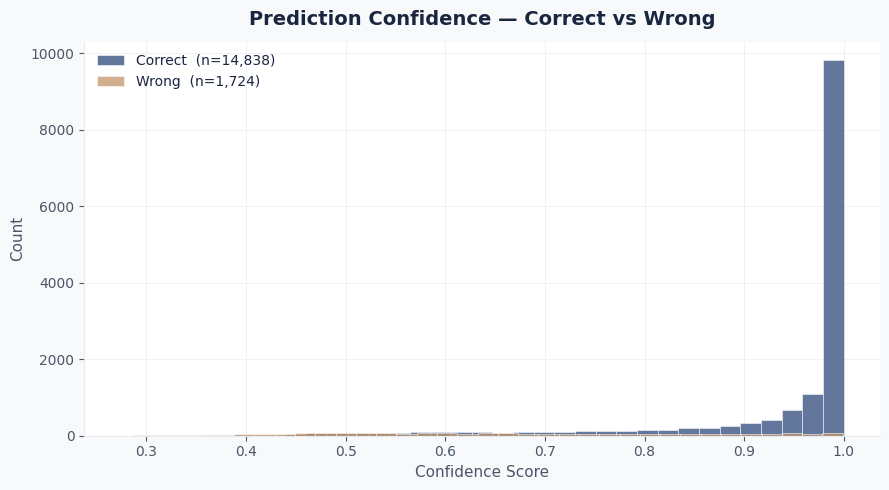

🖼️ Saved: artifacts/lightgbm_knsmote/image/entropy_per_class.png


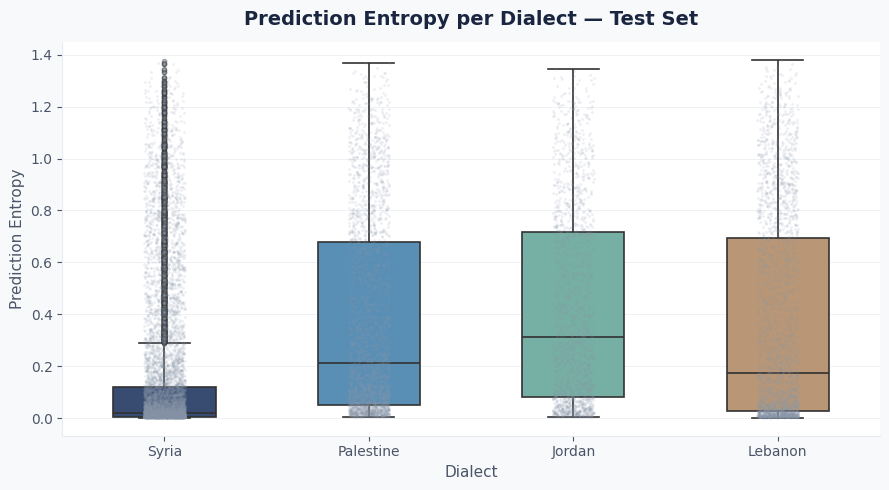

🖼️ Saved: artifacts/lightgbm_knsmote/image/margin_analysis.png


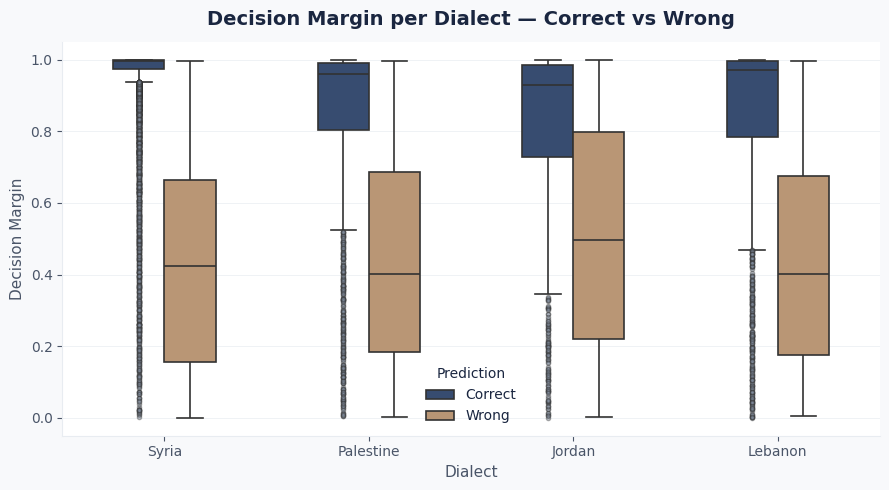

In [62]:
# ── Confidence Distribution ───────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG_COLOR)
ax.set_facecolor(CARD_COLOR)

for correct, color, label in [
    (True,  "#2D4A7A", "Correct"),
    (False, "#C4956A", "Wrong"),
]:
    subset = df_export[df_export["correct"] == correct]["confidence"]
    ax.hist(subset, bins=35, alpha=0.75, color=color,
            label=f"{label}  (n={len(subset):,})",
            edgecolor="white", linewidth=0.5)

ax.set_xlabel("Confidence Score", fontsize=11, color=TEXT_MID)
ax.set_ylabel("Count",            fontsize=11, color=TEXT_MID)
ax.set_title("Prediction Confidence — Correct vs Wrong",
             fontsize=14, fontweight='bold', color=TEXT_DARK)
ax.legend(frameon=False, fontsize=10)
ax.yaxis.grid(True, color=GRID_COLOR)
ax.set_axisbelow(True)

fig.tight_layout()
save_and_show("confidence_distribution")


# ── Entropy per Class ─────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG_COLOR)
ax.set_facecolor(CARD_COLOR)

sns.boxplot(
    x="true_label", y="entropy", data=df_export,
    palette=PALETTE, width=0.5, linewidth=1.2,
    flierprops=dict(marker='o', markerfacecolor=TEXT_LIGHT,
                    markersize=3, alpha=0.4, linestyle='none'),
    ax=ax
)
sns.stripplot(
    x="true_label", y="entropy", data=df_export,
    color=TEXT_LIGHT, alpha=0.15, size=2, jitter=True, ax=ax
)

ax.set_xlabel("Dialect", fontsize=11, color=TEXT_MID)
ax.set_ylabel("Prediction Entropy", fontsize=11, color=TEXT_MID)
ax.set_title("Prediction Entropy per Dialect — Test Set",
             fontsize=14, fontweight='bold', color=TEXT_DARK)
ax.yaxis.grid(True, color=GRID_COLOR)
ax.set_axisbelow(True)

fig.tight_layout()
save_and_show("entropy_per_class")


# ── Margin Analysis ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(9, 5), facecolor=BG_COLOR)
ax.set_facecolor(CARD_COLOR)

sns.boxplot(
    x="true_label", y="margin", hue="correct",
    data=df_export,
    palette={True: "#2D4A7A", False: "#C4956A"},  # ← boolean, bukan string
    hue_order=[True, False],
    width=0.5, linewidth=1.2,
    flierprops=dict(marker='o', markerfacecolor=TEXT_LIGHT,
                    markersize=3, alpha=0.4, linestyle='none'),
    ax=ax
)

handles, _ = ax.get_legend_handles_labels()
ax.legend(handles, ["Correct", "Wrong"],
          frameon=False, fontsize=10, title="Prediction")

ax.set_xlabel("Dialect",         fontsize=11, color=TEXT_MID)
ax.set_ylabel("Decision Margin", fontsize=11, color=TEXT_MID)
ax.set_title("Decision Margin per Dialect — Correct vs Wrong",
             fontsize=14, fontweight='bold', color=TEXT_DARK)
ax.yaxis.grid(True, color=GRID_COLOR)
ax.set_axisbelow(True)

fig.tight_layout()
save_and_show("margin_analysis")

### Lexical Exclusivity Analysis (Jordan, Palestine, Syria/Lebanon)

In [63]:
def exclusivity_analysis(df_src, df_all, src_label,
                         top_n=40, min_freq=10, ratio_thresh=4.0):
    """Token yang paling eksklusif di src_label vs semua negara lain."""
    df_others = df_all[df_all['true_label'] != src_label]
    src_tok, oth_tok = Counter(), Counter()
    for t in df_src['clean_word'].dropna():    src_tok.update(str(t).split())
    for t in df_others['clean_word'].dropna(): oth_tok.update(str(t).split())
    n_src, n_oth = len(df_src), len(df_others)
    results = []
    for tok, cnt_s in src_tok.most_common(500):
        if cnt_s < min_freq or len(tok) < 2: continue
        cnt_o = oth_tok.get(tok, 0)
        ratio = (cnt_s / n_src) / ((cnt_o / n_oth) + 1e-6)
        if ratio > ratio_thresh:
            results.append((tok, cnt_s, cnt_o, ratio))
    results.sort(key=lambda x: -x[3])
    print(f"\n=== TOKEN EKSKLUSIF {src_label.upper()} (vs semua) ===")
    print(f"{'Token':15} | {'Freq':8} | {'Freq Lain':10} | {'Rasio':8}")
    print("-" * 50)
    for tok, cs, co, r in results[:top_n]:
        label_str = "MUTLAK" if co == 0 else f"{r:.1f}x"
        print(f"  {tok:15s} | {cs:<8d} | {co:<10d} | {label_str}")
    return results

# Jordan, Palestine — vs semua negara lain
for country in ["Jordan", "Palestine"]:
    df_country = df_export[df_export['true_label'] == country]
    exclusivity_analysis(df_country, df_export, country)

# Syria vs Lebanon (head-to-head, bukan vs semua — pasangan paling mirip)
def headtohead_exclusivity(df_src, df_cmp, src_label, cmp_label,
                            top_n=15, min_freq=20, ratio_thresh=5.0):
    src_tok, cmp_tok = Counter(), Counter()
    for t in df_src['clean_word'].dropna(): src_tok.update(str(t).split())
    for t in df_cmp['clean_word'].dropna(): cmp_tok.update(str(t).split())
    n_s, n_c = len(df_src), len(df_cmp)
    excl = []
    for tok, cnt in src_tok.most_common(500):
        if cnt < min_freq or len(tok) < 2: continue
        r = (cnt / n_s) / ((cmp_tok.get(tok, 0) / n_c) + 1e-6)
        if r > ratio_thresh:
            excl.append((tok, cnt, cmp_tok.get(tok, 0), r))
    excl.sort(key=lambda x: -x[3])
    print(f"\n=== TOKEN KHAS {src_label.upper()} VS {cmp_label.upper()} ===")
    print(f"{'Token':15} | {'Freq Src':10} | {'Freq Cmp':10} | {'Rasio':8}")
    print("-" * 52)
    for tok, cs, cc, r in excl[:top_n]:
        print(f"  {tok:15s} | {cs:<10d} | {cc:<10d} | {r:.1f}x")
    return excl

df_syria   = df_export[df_export['true_label'] == 'Syria']
df_lebanon = df_export[df_export['true_label'] == 'Lebanon']
headtohead_exclusivity(df_syria,   df_lebanon, "Suriah",  "Lebanon")
headtohead_exclusivity(df_lebanon, df_syria,   "Lebanon", "Suriah")


=== TOKEN EKSKLUSIF JORDAN (vs semua) ===
Token           | Freq     | Freq Lain  | Rasio   
--------------------------------------------------
  يزم             | 10       | 0          | MUTLAK
  هسا             | 27       | 1          | 224.6x
  ونا             | 20       | 1          | 166.4x
  ولله            | 14       | 1          | 116.5x
  انتا            | 37       | 3          | 103.6x
  بالحاره         | 11       | 1          | 91.5x
  ولكو            | 10       | 1          | 83.2x
  همه             | 17       | 2          | 71.2x
  حكالي           | 28       | 5          | 47.1x
  حكيتلو          | 11       | 2          | 46.1x
  مهر             | 11       | 2          | 46.1x
  وجهي            | 31       | 6          | 43.5x
  ابوي            | 21       | 5          | 35.4x
  كلشي            | 15       | 4          | 31.5x
  اخوي            | 24       | 7          | 28.9x
  طب              | 47       | 14         | 28.3x
  خصوصي           | 10       | 3          | 28.0x


[('هيدا', 66, 0, 24381.23383819727),
 ('الرئيس', 50, 0, 18470.63169560399),
 ('قانون', 35, 0, 12929.442186922794),
 ('علقانين', 31, 0, 11451.791651274474),
 ('اللبناني', 30, 0, 11082.379017362395),
 ('بلبنان', 29, 0, 10712.966383450315),
 ('عون', 25, 0, 9235.315847801994),
 ('التيار', 24, 0, 8865.903213889917),
 ('شربل', 23, 0, 8496.490579977835),
 ('هيدي', 23, 0, 8496.490579977835),
 ('دوله', 23, 0, 8496.490579977835),
 ('سوزي', 20, 0, 7388.252678241596),
 ('لبنان', 75, 1, 259.0982572612067),
 ('حلقه', 34, 1, 117.45787662508037),
 ('الشعب', 30, 1, 103.63930290448269),
 ('بلد', 43, 2, 74.62376401265598),
 ('انه', 20, 1, 69.09286860298846),
 ('هل', 32, 2, 55.53396391639515),
 ('برنامج', 31, 2, 53.7985275440078),
 ('نحن', 23, 2, 39.915036564909016),
 ('الطرقات', 22, 2, 38.17960019252166),
 ('مش', 137, 23, 20.763389773319755),
 ('بي', 29, 5, 20.1879656528017),
 ('الدوله', 20, 4, 17.395223592970755),
 ('باسم', 24, 6, 13.927109071580848),
 ('ال', 22, 8, 9.578649170336593),
 ('هشام', 45, 17,

### Visualisasi top-15 eksklusif per dialek


=== TOKEN EKSKLUSIF JORDAN (vs semua) ===
Token           | Freq     | Freq Lain  | Rasio   
--------------------------------------------------
  يزم             | 10       | 0          | MUTLAK
  وانتا           | 9        | 0          | MUTLAK
  عالفيسبوك       | 8        | 0          | MUTLAK
  اصير            | 8        | 0          | MUTLAK
  البلوزه         | 7        | 0          | MUTLAK
  هسا             | 27       | 1          | 224.6x
  ونا             | 20       | 1          | 166.4x
  ولله            | 14       | 1          | 116.5x
  انتا            | 37       | 3          | 103.6x
  بالحاره         | 11       | 1          | 91.5x
  ولكو            | 10       | 1          | 83.2x
  جمب             | 9        | 1          | 74.9x
  بالعقل          | 9        | 1          | 74.9x
  همه             | 17       | 2          | 71.2x
  اعيط            | 8        | 1          | 66.6x

=== TOKEN EKSKLUSIF PALESTINE (vs semua) ===
Token           | Freq     | Freq Lain  | Rasio   

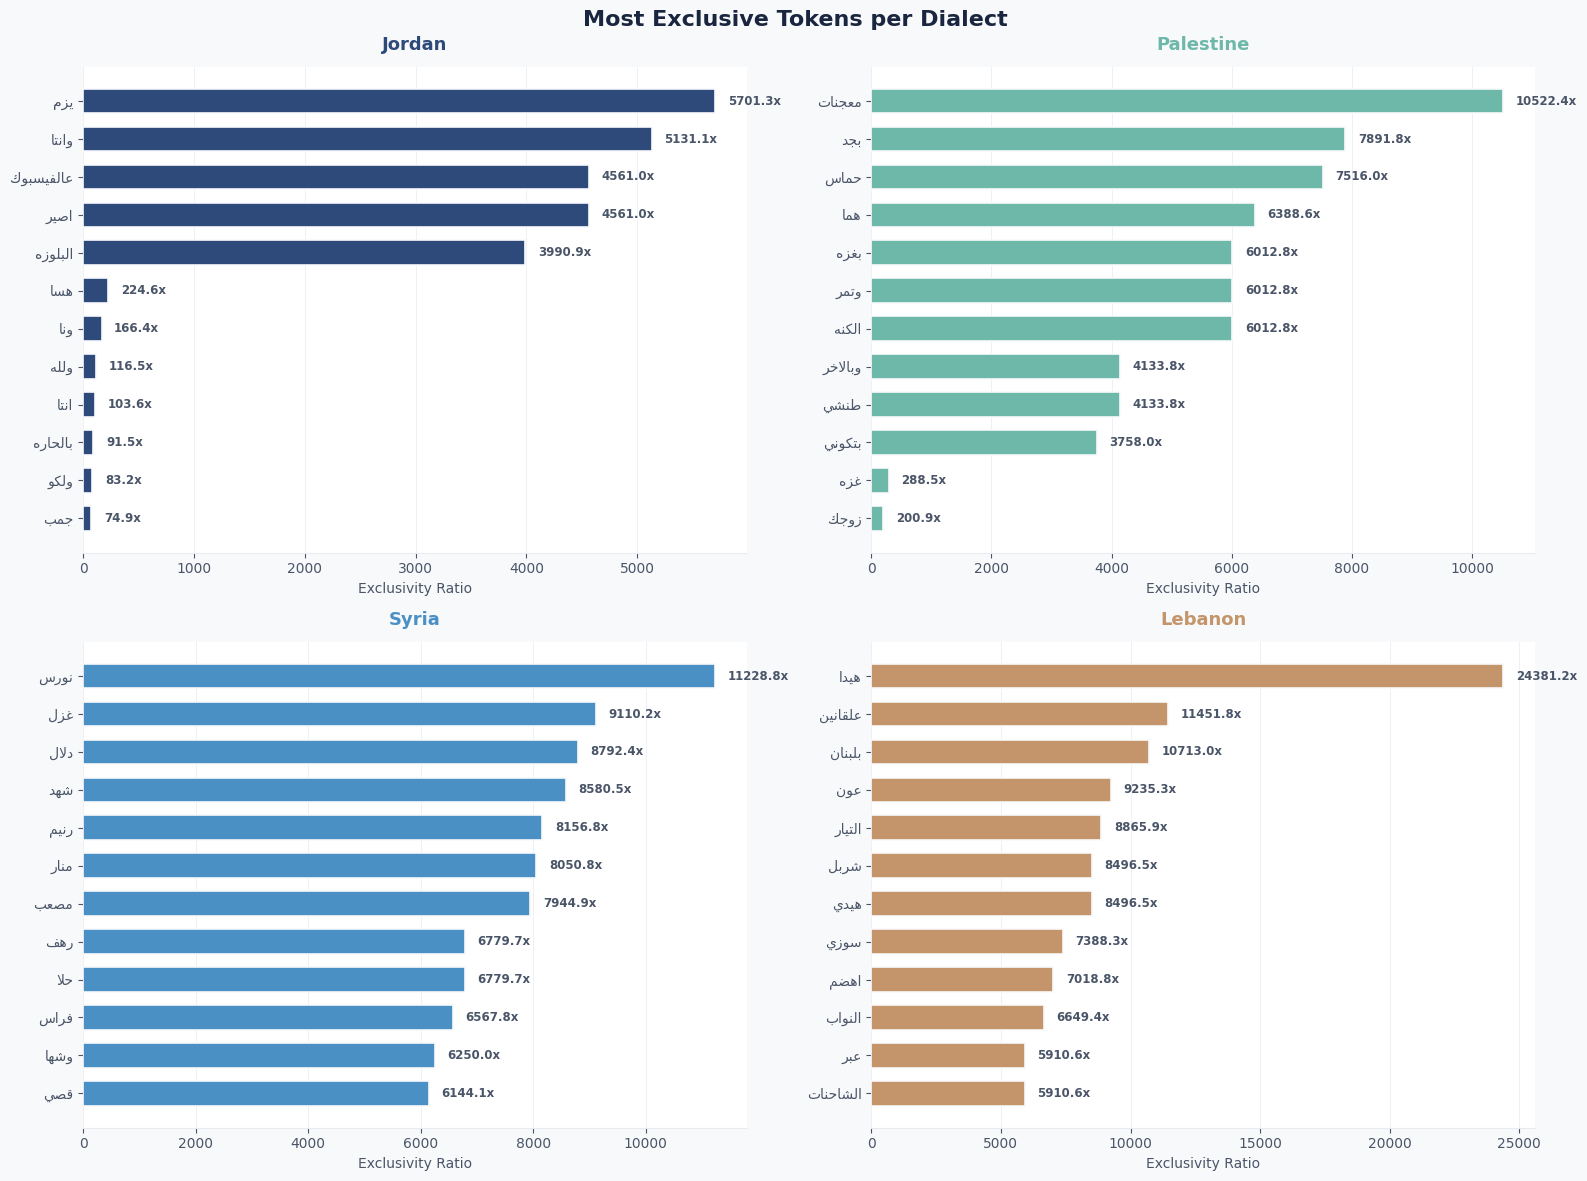

In [64]:
# =========================
# Font setup
# =========================
import matplotlib.pyplot as plt
from matplotlib import font_manager

# Load font
font_ar = font_manager.FontProperties(family='DejaVu Sans')        # Arabic

# =========================
# Arabic reshape
# =========================
import arabic_reshaper
from bidi.algorithm import get_display
import re

def is_arabic(text):
    return bool(re.search(r'[\u0600-\u06FF]', str(text)))

def reshape_ar(text):
    try:
        return get_display(arabic_reshaper.reshape(str(text)))
    except:
        return text

# =========================
# Plot
# =========================
country_colors = {
    "Jordan"   : "#2D4A7A",
    "Palestine": "#6DB8A8",
    "Syria"    : "#4A90C4",
    "Lebanon"  : "#C4956A",
}

fig, axes = plt.subplots(2, 2, figsize=(16, 12), facecolor=BG_COLOR)

fig.suptitle("Most Exclusive Tokens per Dialect",
             fontsize=16, fontweight='bold', color=TEXT_DARK)

for ax, country in zip(axes.flatten(),
                       ["Jordan", "Palestine", "Syria", "Lebanon"]):

    df_c    = df_export[df_export['true_label'] == country]
    results = exclusivity_analysis(df_c, df_export, country,
                                   top_n=15, min_freq=5, ratio_thresh=3.0)

    if not results:
        ax.axis('off')
        continue

    raw_tokens = [r[0] for r in results[:12]]
    tokens = [reshape_ar(t) if is_arabic(t) else t for t in raw_tokens]
    ratios = [r[3] for r in results[:12]]

    color  = country_colors[country]

    bars = ax.barh(tokens[::-1], ratios[::-1],
                   color=color, edgecolor=BG_COLOR,
                   linewidth=1.2, height=0.65)

    # 🔥 SET FONT PER LABEL
    ax.set_yticklabels(tokens[::-1])
    for label, raw in zip(ax.get_yticklabels(), raw_tokens[::-1]):
        if is_arabic(raw):
            label.set_fontproperties(font_ar)

    # value text
    for bar, val in zip(bars, ratios[::-1]):
        ax.text(bar.get_width() + max(ratios)*0.02,
                bar.get_y() + bar.get_height()/2,
                f"{val:.1f}x",
                va='center', ha='left',
                fontsize=8.5, color=TEXT_MID,
                fontweight='bold')

    ax.spines[['left','top','right']].set_visible(False)
    ax.xaxis.grid(True, color=GRID_COLOR, linewidth=0.7)
    ax.yaxis.grid(False)
    ax.set_axisbelow(True)

    ax.set_facecolor(CARD_COLOR)
    ax.set_title(country, fontsize=13,
                 fontweight='bold', color=color)

    ax.set_xlabel("Exclusivity Ratio",
                  fontsize=10, color=TEXT_MID,
                  )

    ax.tick_params(axis='y', labelsize=10)

fig.tight_layout()
save_and_show("token_exclusivity")


=== TOKEN EKSKLUSIF JORDAN (vs semua) ===
Token           | Freq     | Freq Lain  | Rasio   
--------------------------------------------------
  يزم             | 10       | 0          | MUTLAK
  وانتا           | 9        | 0          | MUTLAK
  عالفيسبوك       | 8        | 0          | MUTLAK
  اصير            | 8        | 0          | MUTLAK
  البلوزه         | 7        | 0          | MUTLAK
  هسا             | 27       | 1          | 224.6x
  ونا             | 20       | 1          | 166.4x
  ولله            | 14       | 1          | 116.5x
  انتا            | 37       | 3          | 103.6x
  بالحاره         | 11       | 1          | 91.5x
  ولكو            | 10       | 1          | 83.2x
  جمب             | 9        | 1          | 74.9x
  بالعقل          | 9        | 1          | 74.9x
  همه             | 17       | 2          | 71.2x
  اعيط            | 8        | 1          | 66.6x
🖼️ Saved: artifacts/lightgbm_knsmote/image/token_exclusivity_jordan.png


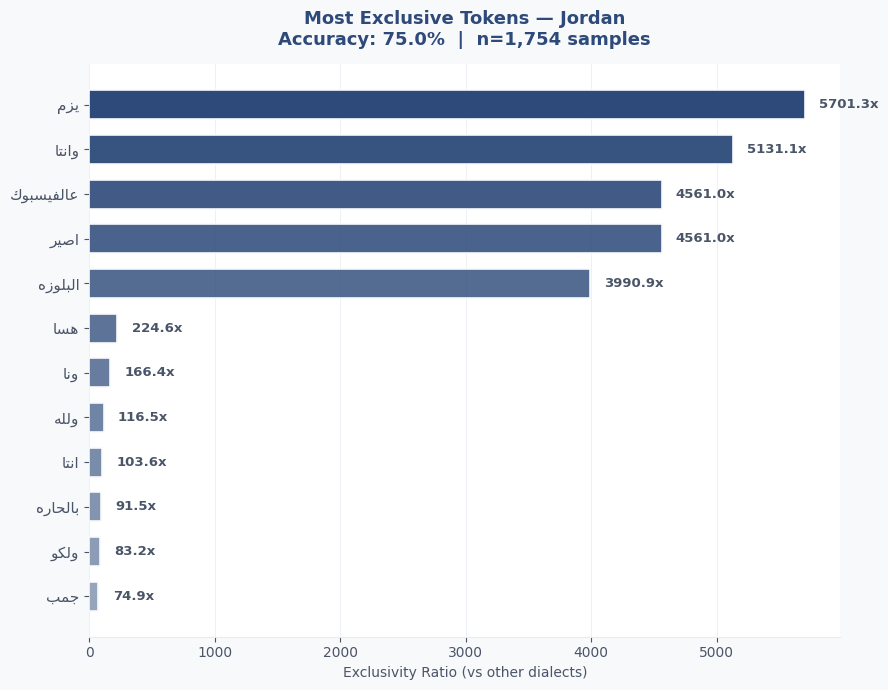


=== TOKEN EKSKLUSIF PALESTINE (vs semua) ===
Token           | Freq     | Freq Lain  | Rasio   
--------------------------------------------------
  معجنات          | 28       | 0          | MUTLAK
  بجد             | 21       | 0          | MUTLAK
  حماس            | 20       | 0          | MUTLAK
  هما             | 17       | 0          | MUTLAK
  بغزه            | 16       | 0          | MUTLAK
  وتمر            | 16       | 0          | MUTLAK
  الكنه           | 16       | 0          | MUTLAK
  وبالاخر         | 11       | 0          | MUTLAK
  طنشي            | 11       | 0          | MUTLAK
  بتكوني          | 10       | 0          | MUTLAK
  غزه             | 56       | 1          | 288.5x
  زوجك            | 39       | 1          | 200.9x
  هادا            | 37       | 1          | 190.6x
  علشان           | 17       | 1          | 87.6x
  زيك             | 16       | 1          | 82.4x
🖼️ Saved: artifacts/lightgbm_knsmote/image/token_exclusivity_palestine.png


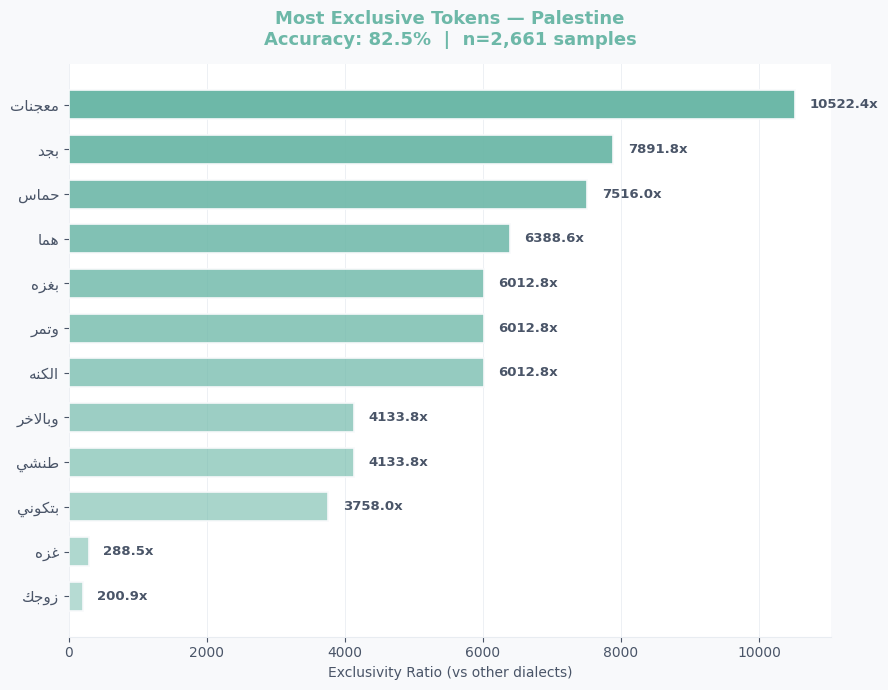


=== TOKEN EKSKLUSIF SYRIA (vs semua) ===
Token           | Freq     | Freq Lain  | Rasio   
--------------------------------------------------
  نورس            | 106      | 0          | MUTLAK
  غزل             | 86       | 0          | MUTLAK
  دلال            | 83       | 0          | MUTLAK
  شهد             | 81       | 0          | MUTLAK
  رنيم            | 77       | 0          | MUTLAK
  منار            | 76       | 0          | MUTLAK
  مصعب            | 75       | 0          | MUTLAK
  رهف             | 64       | 0          | MUTLAK
  حلا             | 64       | 0          | MUTLAK
  فراس            | 62       | 0          | MUTLAK
  وشها            | 59       | 0          | MUTLAK
  قصي             | 58       | 0          | MUTLAK
  منال            | 54       | 0          | MUTLAK
  رفيف            | 53       | 0          | MUTLAK
  حاتم            | 53       | 0          | MUTLAK
🖼️ Saved: artifacts/lightgbm_knsmote/image/token_exclusivity_syria.png


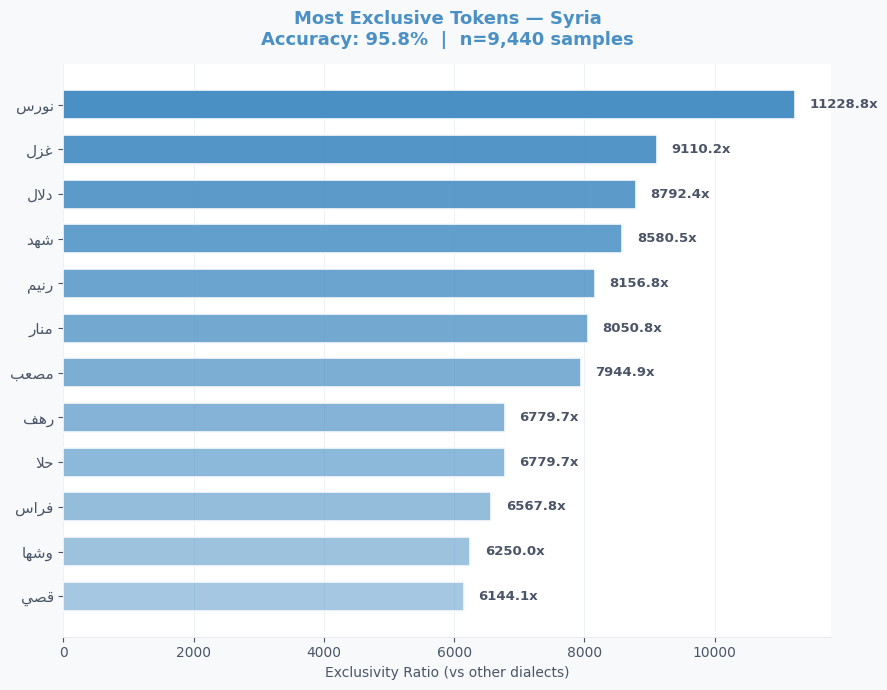


=== TOKEN EKSKLUSIF LEBANON (vs semua) ===
Token           | Freq     | Freq Lain  | Rasio   
--------------------------------------------------
  هيدا            | 66       | 0          | MUTLAK
  علقانين         | 31       | 0          | MUTLAK
  بلبنان          | 29       | 0          | MUTLAK
  عون             | 25       | 0          | MUTLAK
  التيار          | 24       | 0          | MUTLAK
  شربل            | 23       | 0          | MUTLAK
  هيدي            | 23       | 0          | MUTLAK
  سوزي            | 20       | 0          | MUTLAK
  اهضم            | 19       | 0          | MUTLAK
  النواب          | 18       | 0          | MUTLAK
  عبر             | 16       | 0          | MUTLAK
  الشاحنات        | 16       | 0          | MUTLAK
  ياخور           | 15       | 0          | MUTLAK
  هلق             | 15       | 0          | MUTLAK
  السياسيين       | 14       | 0          | MUTLAK
🖼️ Saved: artifacts/lightgbm_knsmote/image/token_exclusivity_lebanon.png


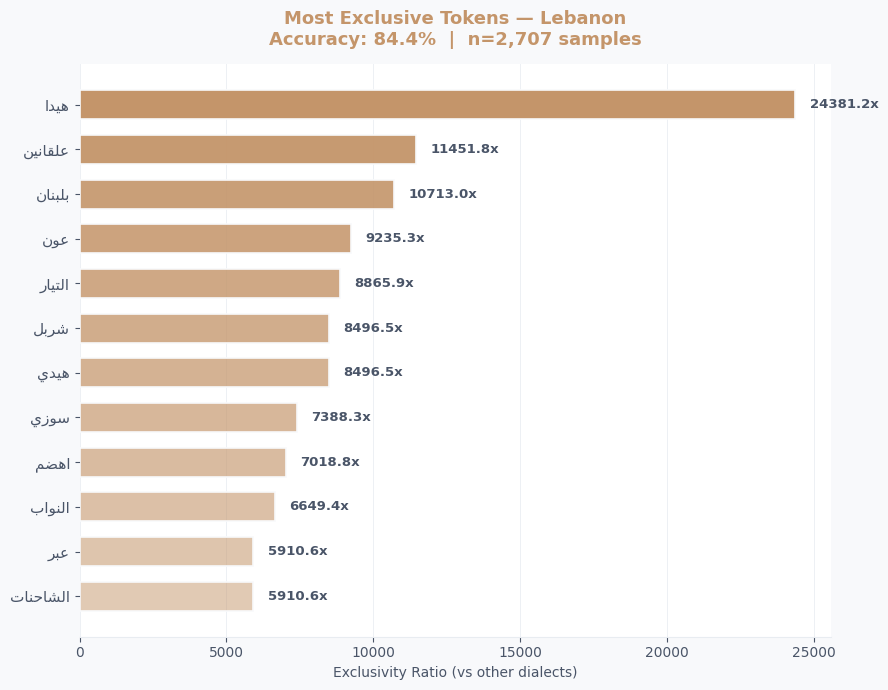

In [65]:
import re
from matplotlib import font_manager

# =========================
# Plot per country
# =========================
for country in ["Jordan", "Palestine", "Syria", "Lebanon"]:

    df_c    = df_export[df_export['true_label'] == country]
    results = exclusivity_analysis(df_c, df_export, country,
                                   top_n=15, min_freq=5, ratio_thresh=3.0)

    if not results:
        print(f"⚠️ No results for {country}, skipping.")
        continue

    raw_tokens = [r[0] for r in results[:12]]
    tokens = [reshape_ar(t) if is_arabic(t) else t for t in raw_tokens]
    ratios = [r[3] for r in results[:12]]
    color  = country_colors[country]

    n_bars = len(tokens)
    bar_colors = [
        color + f"{int(255 * (0.5 + 0.5 * (i / max(n_bars-1,1)))):02x}"
        for i in range(n_bars)
    ]

    fig, ax = plt.subplots(figsize=(9, 7), facecolor=BG_COLOR)
    ax.set_facecolor(CARD_COLOR)

    bars = ax.barh(tokens[::-1], ratios[::-1],
                   color=bar_colors,
                   edgecolor=BG_COLOR,
                   linewidth=1.2,
                   height=0.65)

    # 🔥 SET FONT PER LABEL (INI KUNCI)
    ax.set_yticklabels(tokens[::-1])
    for label, raw in zip(ax.get_yticklabels(), raw_tokens[::-1]):
        if is_arabic(raw):
            label.set_fontproperties(font_ar)
        else:
            label.set_fontproperties(font_en)

    # value text (pakai font latin)
    for bar, val in zip(bars, ratios[::-1]):
        ax.text(
            bar.get_width() + max(ratios) * 0.02,
            bar.get_y() + bar.get_height() / 2,
            f"{val:.1f}x",
            va='center',
            ha='left',
            fontsize=9.5,
            color=TEXT_MID,
            fontweight='bold',

        )

    # subtitle info
    n_correct = (df_export[df_export['true_label'] == country]['correct']).sum()
    n_total   = len(df_export[df_export['true_label'] == country])
    acc       = n_correct / n_total * 100

    ax.set_title(
        f"Most Exclusive Tokens — {country}\n"
        f"Accuracy: {acc:.1f}%  |  n={n_total:,} samples",
        fontsize=13,
        fontweight='bold',
        color=color,
        pad=14,

    )

    ax.set_xlabel(
        "Exclusivity Ratio (vs other dialects)",
        fontsize=10,
        color=TEXT_MID,

    )

    ax.spines[['left','top','right']].set_visible(False)
    ax.xaxis.grid(True, color=GRID_COLOR, linewidth=0.7)
    ax.yaxis.grid(False)
    ax.set_axisbelow(True)

    ax.tick_params(axis='y', labelsize=11)
    ax.tick_params(axis='x', labelsize=10)

    fig.tight_layout()
    save_and_show(f"token_exclusivity_{country.lower()}")

## Demo

In [66]:
def predict_custom(text, model, feat, le, top_n=4):
    # Build input DataFrame sesuai format yang diharapkan feat.transform()
    clean_w = clean_noise(text)
    clean_c = clean_char(text)

    df_input = pd.DataFrame({
        "text"       : [text],
        "clean_word" : [clean_w],
        "clean_char" : [clean_c],
    })

    # Transform & predict
    X_input  = feat.transform(df_input)

    if drop_list:
        X_input, _ = drop_blocks(X_input, block_slices, drop_list)

    proba    = model.predict_proba(X_input, num_iteration=model.best_iteration_)[0]
    pred_idx = np.argmax(proba)

    # Display hasil
    print("=" * 45)
    print(f"Input   : {text}")
    print(f"Clean   : {clean_w}")
    print("-" * 45)
    print(f"Prediksi: {le.classes_[pred_idx]}  ({proba[pred_idx]*100:.1f}%)")
    print("-" * 45)
    print("Probabilitas semua kelas:")
    for idx in np.argsort(proba)[::-1]:
        bar = "█" * int(proba[idx] * 30)
        print(f"  {le.classes_[idx]:12s}: {proba[idx]*100:5.1f}%  {bar}")
    print("=" * 45)

    return le.classes_[pred_idx], proba


# ── Ganti teks di sini ──────────────────────────────────
sample_texts = [
    "شو بدك تاكل اليوم",
    "ايش تبي تاكل اليوم",
    "شو عملت امبارح",
]

for text in sample_texts:
    predict_custom(text, model, feat, le)
    print()

Input   : شو بدك تاكل اليوم
Clean   : شو بدك تاكل اليوم
---------------------------------------------
Prediksi: Lebanon  (50.7%)
---------------------------------------------
Probabilitas semua kelas:
  Lebanon     :  50.7%  ███████████████
  Syria       :  45.5%  █████████████
  Jordan      :   2.3%  
  Palestine   :   1.5%  

Input   : ايش تبي تاكل اليوم
Clean   : ايش تبي تاكل اليوم
---------------------------------------------
Prediksi: Palestine  (51.8%)
---------------------------------------------
Probabilitas semua kelas:
  Palestine   :  51.8%  ███████████████
  Lebanon     :  42.1%  ████████████
  Jordan      :   3.6%  █
  Syria       :   2.5%  

Input   : شو عملت امبارح
Clean   : شو عملت امبارح
---------------------------------------------
Prediksi: Jordan  (87.4%)
---------------------------------------------
Probabilitas semua kelas:
  Jordan      :  87.4%  ██████████████████████████
  Syria       :  10.4%  ███
  Lebanon     :   1.2%  
  Palestine   :   0.9%  



In [67]:
predict_custom("شو بدك", model, feat, le)

Input   : شو بدك
Clean   : شو بدك
---------------------------------------------
Prediksi: Jordan  (69.4%)
---------------------------------------------
Probabilitas semua kelas:
  Jordan      :  69.4%  ████████████████████
  Syria       :  20.0%  ██████
  Lebanon     :  10.2%  ███
  Palestine   :   0.4%  


('Jordan', array([0.69370758, 0.10174089, 0.00417705, 0.20037447]))